# Detekcja Phishingu - XGBoost

Ten notebook zawiera implementację i analizę modelu XGBoost do wykrywania phishingu.

## 1. Import bibliotek i konfiguracja


In [1]:
from pathlib import Path
import os
import sys

start_dir = Path.cwd().resolve()
backend_root = None
for candidate in (start_dir, *start_dir.parents):
    if (candidate / 'utils').is_dir() and (candidate / 'notebooks').is_dir():
        backend_root = candidate
        break
    nested_backend = candidate / 'backend'
    if (nested_backend / 'utils').is_dir() and (nested_backend / 'notebooks').is_dir():
        backend_root = nested_backend
        break

if backend_root is None:
    raise RuntimeError(
        f'Cannot locate backend root from Jupyter working directory: {start_dir}'
    )

notebooks_dir = backend_root / 'notebooks'
os.chdir(notebooks_dir)
if str(backend_root) not in sys.path:
    sys.path.insert(0, str(backend_root))

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import pickle

import xgboost as xgb
import importlib

if 'utils.resource_monitor' in sys.modules:
    importlib.reload(sys.modules['utils.resource_monitor'])

if 'utils.isolated_training' in sys.modules:
    importlib.reload(sys.modules['utils.isolated_training'])
from utils.isolated_training import fit_model_isolated
if 'utils.notebook_plot_style' in sys.modules:
    importlib.reload(sys.modules['utils.notebook_plot_style'])

from utils.notebook_plot_style import (
    plot_sample_probability_prediction,
    plot_training_time_comparison,
    save_comparison_figure,
    feature_count_comparison_rows,
    plot_final_train_test_metric_groups,
    resource_baseline_summary,
    classification_metric_sets,
    DATASET_SUBDIRS,
    dataset_display_name,
    dataset_key,
    plot_confusion_matrix,
    plot_parameter_train_test_error,
    plot_roc_curve,
    plot_feature_ranking,
    plot_resource_usage_separate,
    plot_score_curve,
    remove_dataset_figure,
    save_dataset_figure,
)
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, learning_curve, validation_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                           roc_auc_score, confusion_matrix, log_loss)
from utils.feature_names import get_readable_name
from utils.split_dataset_loader import feature_columns


PLOTS_DIR = backend_root.parent / 'results' / 'original' / 'plots' / 'xgboost'
MODELS_DIR = "../models/xgboost"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

DATASET_SUBDIR = DATASET_SUBDIRS
os.makedirs(f'{PLOTS_DIR}/full', exist_ok=True)
os.makedirs(f'{PLOTS_DIR}/optimized', exist_ok=True)

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['figure.figsize'] = (12, 7)

np.random.seed(42)

print("Biblioteki zostały zaimportowane pomyślnie!")


Biblioteki zostały zaimportowane pomyślnie!


## 2. Wczytanie i eksploracja danych (oba zbiory)


In [2]:
df_original = pd.read_csv('../data/dataset_full_balanced.csv')
df_optimized = pd.read_csv('../data/dataset_optimized_balanced.csv')

datasets = {
    'Pełny zbiór': df_original,
    'Zoptymalizowany zbiór': df_optimized
}

print("="*60)
print("PORÓWNANIE ZBIORÓW DANYCH")
print("="*60)

for name, df in datasets.items():
    print(f"\n{'='*60}")
    print(f"Zbiór: {name.upper()}")
    print(f"{'='*60}")
    print(f"Rozmiar zbioru: {df.shape}")
    print(f"Liczba cech: {len(df.columns)-1}")

    print(f"\nPierwsze 5 kolumn: {list(df.columns[:5])}")
    print(f"Ostatnie 5 kolumn: {list(df.columns[-5:])}")

    label_counts = df['phishing'].value_counts()
    print(f"\nRozkład etykiet:")
    print(f"URL oznaczone jako bezpieczne: {label_counts[0]:,} ({label_counts[0]/len(df)*100:.1f}%)")
    print(f"URL oznaczone jako phisingowe: {label_counts[1]:,} ({label_counts[1]/len(df)*100:.1f}%)")

    print(f"\nInformacje o zbiorze:")
    print(f"- Łączna liczba próbek: {len(df):,}")
    print(f"- Liczba cech: {len(df.columns)-1}")
    print(f"- Brakujące wartości: {df.isnull().sum().sum()}")
    print(f"- Duplikaty: {df.duplicated().sum()}")


PORÓWNANIE ZBIORÓW DANYCH

Zbiór: PEŁNY ZBIÓR
Rozmiar zbioru: (61294, 112)
Liczba cech: 111

Pierwsze 5 kolumn: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url']
Ostatnie 5 kolumn: ['qty_redirects', 'url_google_index', 'domain_google_index', 'url_shortened', 'phishing']

Rozkład etykiet:
URL oznaczone jako bezpieczne: 30,647 (50.0%)
URL oznaczone jako phisingowe: 30,647 (50.0%)

Informacje o zbiorze:
- Łączna liczba próbek: 61,294
- Liczba cech: 111
- Brakujące wartości: 0
- Duplikaty: 713

Zbiór: ZOPTYMALIZOWANY ZBIÓR
Rozmiar zbioru: (60994, 75)
Liczba cech: 74

Pierwsze 5 kolumn: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url']
Ostatnie 5 kolumn: ['ttl_hostname', 'tls_ssl_certificate', 'qty_redirects', 'url_shortened', 'phishing']

Rozkład etykiet:
URL oznaczone jako bezpieczne: 30,497 (50.0%)
URL oznaczone jako phisingowe: 30,497 (50.0%)

Informacje o zbiorze:
- Łączna liczba próbek: 60,994


## 3. Przygotowanie cech i etykiet (dla obu zbiorów)


In [3]:
data_splits = {}

for name, df in datasets.items():
    columns = feature_columns(df)
    X = df[columns]
    y = df['phishing']

    print(f"\n{'='*60}")
    print(f"Przygotowanie danych: {name.upper()}")
    print(f"{'='*60}")
    print(f"  Liczba cech: {X.shape[1]}")
    print(f"  Liczba próbek: {X.shape[0]:,}")

    print(f"\nRozkład klas:")
    for label, count in y.value_counts().items():
        percentage = count / len(y) * 100
        label_name = "Legalny URL" if label == 0 else "Phishing"
        print(f"  {label} ({label_name}): {count:,} ({percentage:.1f}%)")

    class_ratio = y.value_counts().min() / y.value_counts().max()
    scale_pos_weight = y.value_counts()[0] / y.value_counts()[1]
    print(f"\nObliczony scale_pos_weight dla XGBoost: {scale_pos_weight:.2f}")

    data_splits[name] = {
        'X': X,
        'y': y,
        'feature_count': X.shape[1],
        'scale_pos_weight': scale_pos_weight
    }



Przygotowanie danych: PEŁNY ZBIÓR
  Liczba cech: 111
  Liczba próbek: 61,294

Rozkład klas:
  0 (Legalny URL): 30,647 (50.0%)
  1 (Phishing): 30,647 (50.0%)

Obliczony scale_pos_weight dla XGBoost: 1.00

Przygotowanie danych: ZOPTYMALIZOWANY ZBIÓR
  Liczba cech: 74
  Liczba próbek: 60,994

Rozkład klas:
  1 (Phishing): 30,497 (50.0%)
  0 (Legalny URL): 30,497 (50.0%)

Obliczony scale_pos_weight dla XGBoost: 1.00


## 4. Podział danych na zbiory uczący i testowy (dla obu zbiorów)


In [4]:
for name in data_splits.keys():
    X = data_splits[name]['X']
    y = data_splits[name]['y']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    data_splits[name]['X_train'] = X_train
    data_splits[name]['X_test'] = X_test
    data_splits[name]['y_train'] = y_train
    data_splits[name]['y_test'] = y_test

    print(f"\n{'='*60}")
    print(f"Podział danych: {name.upper()}")
    print(f"{'='*60}")
    print(f"Zbiór uczący: {X_train.shape[0]:,} próbek ({X_train.shape[0]/len(X)*100:.1f}%)")
    print(f"Zbiór testowy: {X_test.shape[0]:,} próbek ({X_test.shape[0]/len(X)*100:.1f}%)")

    print(f"\nRozkład klas w zbiorze uczącym:")
    train_counts = y_train.value_counts()
    print(f"  Legalny URL: {train_counts[0]:,} ({train_counts[0]/len(y_train)*100:.1f}%)")
    print(f"  Phishing: {train_counts[1]:,} ({train_counts[1]/len(y_train)*100:.1f}%)")

    print(f"\nRozkład klas w zbiorze testowym:")
    test_counts = y_test.value_counts()
    print(f"  Legalny URL: {test_counts[0]:,} ({test_counts[0]/len(y_test)*100:.1f}%)")
    print(f"  Phishing: {test_counts[1]:,} ({test_counts[1]/len(y_test)*100:.1f}%)")


Podział danych: PEŁNY ZBIÓR
Zbiór uczący: 49,035 próbek (80.0%)
Zbiór testowy: 12,259 próbek (20.0%)

Rozkład klas w zbiorze uczącym:
  Legalny URL: 24,517 (50.0%)
  Phishing: 24,518 (50.0%)

Rozkład klas w zbiorze testowym:
  Legalny URL: 6,130 (50.0%)
  Phishing: 6,129 (50.0%)

Podział danych: ZOPTYMALIZOWANY ZBIÓR
Zbiór uczący: 48,795 próbek (80.0%)
Zbiór testowy: 12,199 próbek (20.0%)

Rozkład klas w zbiorze uczącym:
  Legalny URL: 24,397 (50.0%)
  Phishing: 24,398 (50.0%)

Rozkład klas w zbiorze testowym:
  Legalny URL: 6,100 (50.0%)
  Phishing: 6,099 (50.0%)


## 5. Optymalizacja hiperparametrów (dla obu zbiorów)


In [5]:
optimization_results = {}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{'='*80}")
    print(f"OPTYMALIZACJA HIPERPARAMETRÓW - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train = data_splits[dataset_name]['X_train']
    X_test = data_splits[dataset_name]['X_test']
    y_train = data_splits[dataset_name]['y_train']
    y_test = data_splits[dataset_name]['y_test']
    scale_pos_weight = data_splits[dataset_name]['scale_pos_weight']

    print(f"Stosunek klas (negatywne/pozytywne): {scale_pos_weight:.2f}")

    param_grids = [
        {
            'name': 'Optymalizacja learning_rate i n_estimators',
            'params': {
                'learning_rate': [0.01, 0.1, 0.3],
                'n_estimators': [100, 200, 300],
                'max_depth': [6],
                'min_child_weight': [1],
                'subsample': [1.0],
                'colsample_bytree': [1.0],
                'scale_pos_weight': [scale_pos_weight]
            }
        },
        {
            'name': 'Optymalizacja max_depth i min_child_weight',
            'params': {
                'learning_rate': [0.1],
                'n_estimators': [200],
                'max_depth': [3, 6, 9],
                'min_child_weight': [1, 3, 5],
                'subsample': [1.0],
                'colsample_bytree': [1.0],
                'scale_pos_weight': [scale_pos_weight]
            }
        },
        {
            'name': 'Optymalizacja subsample i colsample_bytree',
            'params': {
                'learning_rate': [0.1],
                'n_estimators': [200],
                'max_depth': [6],
                'min_child_weight': [1],
                'subsample': [0.6, 0.8, 1.0],
                'colsample_bytree': [0.6, 0.8, 1.0],
                'scale_pos_weight': [scale_pos_weight]
            }
        }
    ]

    best_overall_score = 0
    best_overall_params = None
    best_grid_name = ""

    start_time = time.time()

    for i, grid_config in enumerate(param_grids):
        grid_name = grid_config['name']
        param_grid = grid_config['params']

        combinations = (len(param_grid['learning_rate']) *
                       len(param_grid['n_estimators']) *
                       len(param_grid['max_depth']) *
                       len(param_grid['min_child_weight']) *
                       len(param_grid['subsample']) *
                       len(param_grid['colsample_bytree']))

        print(f"\n{'='*60}")
        print(f"Konfiguracja {i+1}/{len(param_grids)}: {grid_name}")
        print(f"{'='*60}")
        print(f"Testowanie {combinations} kombinacji parametrów...")

        grid_start_time = time.time()

        grid_search = GridSearchCV(
            xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss', use_label_encoder=False),
            param_grid,
            cv=5,
            scoring='roc_auc',
            n_jobs=-1,
            verbose=0
        )

        grid_search.fit(X_train, y_train)

        grid_time = time.time() - grid_start_time

        print(f"\nNajlepsze parametry: {grid_search.best_params_}")
        print(f"Najlepszy CV ROC-AUC: {grid_search.best_score_:.4f}")
        print(f"Czas wykonania: {grid_time:.2f} sekund")

        if grid_search.best_score_ > best_overall_score:
            best_overall_score = grid_search.best_score_
            best_overall_params = grid_search.best_params_
            best_grid_name = grid_name

    optimization_time = time.time() - start_time

    print(f"\n{'='*60}")
    print(f"PODSUMOWANIE OPTYMALIZACJI - {dataset_name.upper()}")
    print(f"{'='*60}")
    print(f"Całkowity czas optymalizacji: {optimization_time:.2f} sekund ({optimization_time/60:.1f} minut)")
    print(f"Najlepszy CV ROC-AUC: {best_overall_score:.4f}")
    print(f"Najlepsza konfiguracja: {best_grid_name}")
    print(f"Najlepsze parametry:")
    for param, value in best_overall_params.items():
        print(f"   {param}: {value}")

    if best_overall_score >= 0.95:
        print("\n✅ Doskonała wydajność CV (≥95%)")
    elif best_overall_score >= 0.90:
        print("\n✅ Bardzo dobra wydajność CV (≥90%)")
    elif best_overall_score >= 0.85:
        print("\n✅ Dobra wydajność CV (≥85%)")
    else:
        print("\n⚠️ Wydajność CV wymaga poprawy (<85%)")

    optimization_results[dataset_name] = {
        'best_params': best_overall_params,
        'best_score': best_overall_score,
        'best_grid_name': best_grid_name,
        'optimization_time': optimization_time,
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test
    }

print(f"\n{'='*80}")
print("ZAKOŃCZONO OPTYMALIZACJĘ DLA OBU ZBIORÓW")
print(f"{'='*80}")


OPTYMALIZACJA HIPERPARAMETRÓW - PEŁNY ZBIÓR
Stosunek klas (negatywne/pozytywne): 1.00

Konfiguracja 1/3: Optymalizacja learning_rate i n_estimators
Testowanie 9 kombinacji parametrów...



Najlepsze parametry: {'colsample_bytree': 1.0, 'learning_rate': 0.3, 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 300, 'scale_pos_weight': np.float64(1.0), 'subsample': 1.0}
Najlepszy CV ROC-AUC: 0.9948
Czas wykonania: 10.28 sekund

Konfiguracja 2/3: Optymalizacja max_depth i min_child_weight
Testowanie 9 kombinacji parametrów...



Najlepsze parametry: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 9, 'min_child_weight': 1, 'n_estimators': 200, 'scale_pos_weight': np.float64(1.0), 'subsample': 1.0}
Najlepszy CV ROC-AUC: 0.9948
Czas wykonania: 8.13 sekund

Konfiguracja 3/3: Optymalizacja subsample i colsample_bytree
Testowanie 9 kombinacji parametrów...



Najlepsze parametry: {'colsample_bytree': 0.6, 'learning_rate': 0.1, 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 200, 'scale_pos_weight': np.float64(1.0), 'subsample': 0.8}
Najlepszy CV ROC-AUC: 0.9945
Czas wykonania: 8.35 sekund

PODSUMOWANIE OPTYMALIZACJI - PEŁNY ZBIÓR
Całkowity czas optymalizacji: 26.76 sekund (0.4 minut)
Najlepszy CV ROC-AUC: 0.9948
Najlepsza konfiguracja: Optymalizacja max_depth i min_child_weight
Najlepsze parametry:
   colsample_bytree: 1.0
   learning_rate: 0.1
   max_depth: 9
   min_child_weight: 1
   n_estimators: 200
   scale_pos_weight: 1.0
   subsample: 1.0

✅ Doskonała wydajność CV (≥95%)

OPTYMALIZACJA HIPERPARAMETRÓW - ZOPTYMALIZOWANY ZBIÓR
Stosunek klas (negatywne/pozytywne): 1.00

Konfiguracja 1/3: Optymalizacja learning_rate i n_estimators
Testowanie 9 kombinacji parametrów...



Najlepsze parametry: {'colsample_bytree': 1.0, 'learning_rate': 0.3, 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 300, 'scale_pos_weight': np.float64(1.0), 'subsample': 1.0}
Najlepszy CV ROC-AUC: 0.9947
Czas wykonania: 6.65 sekund

Konfiguracja 2/3: Optymalizacja max_depth i min_child_weight
Testowanie 9 kombinacji parametrów...



Najlepsze parametry: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 9, 'min_child_weight': 1, 'n_estimators': 200, 'scale_pos_weight': np.float64(1.0), 'subsample': 1.0}
Najlepszy CV ROC-AUC: 0.9948
Czas wykonania: 6.22 sekund

Konfiguracja 3/3: Optymalizacja subsample i colsample_bytree
Testowanie 9 kombinacji parametrów...



Najlepsze parametry: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 200, 'scale_pos_weight': np.float64(1.0), 'subsample': 0.6}
Najlepszy CV ROC-AUC: 0.9943
Czas wykonania: 6.52 sekund

PODSUMOWANIE OPTYMALIZACJI - ZOPTYMALIZOWANY ZBIÓR
Całkowity czas optymalizacji: 19.39 sekund (0.3 minut)
Najlepszy CV ROC-AUC: 0.9948
Najlepsza konfiguracja: Optymalizacja max_depth i min_child_weight
Najlepsze parametry:
   colsample_bytree: 1.0
   learning_rate: 0.1
   max_depth: 9
   min_child_weight: 1
   n_estimators: 200
   scale_pos_weight: 1.0
   subsample: 1.0

✅ Doskonała wydajność CV (≥95%)

ZAKOŃCZONO OPTYMALIZACJĘ DLA OBU ZBIORÓW


## 5.1. Trening i monitorowanie zasobów systemowych (RAM i CPU)


In [6]:
results_for_datasets = {}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{'='*80}")
    print(f"TRENING Z MONITOROWANIEM ZASOBÓW - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train = optimization_results[dataset_name]['X_train']
    X_test = optimization_results[dataset_name]['X_test']
    y_train = optimization_results[dataset_name]['y_train']
    y_test = optimization_results[dataset_name]['y_test']
    best_params = optimization_results[dataset_name]['best_params']

    print(f"Trenowanie na pełnym zbiorze uczącym: {X_train.shape[0]:,} próbek, {X_train.shape[1]} cech")
    print(f"Parametry modelu: {best_params}")

    best_model = xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss', use_label_encoder=False, **best_params)
    isolated_result = fit_model_isolated(
        best_model, X_train, y_train, interval=0.05,
    )
    best_model = isolated_result.model
    resource_monitor = isolated_result.monitor
    training_time = isolated_result.training_time
    stats = isolated_result.stats

    results_for_datasets[dataset_name] = {
        'model': best_model,
        'best_params': best_params,
        'best_score': optimization_results[dataset_name]['best_score'],
        'best_grid_name': optimization_results[dataset_name]['best_grid_name'],
        'optimization_time': optimization_results[dataset_name]['optimization_time'],
        'training_time': training_time,
        'resource_monitor': resource_monitor,
        'resource_stats': stats,
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test
    }

    file_suffix = 'full' if dataset_name == 'Pełny zbiór' else 'optimized'
    checkpoint_path = f'{MODELS_DIR}/xgboost_model_{file_suffix}.pkl'
    checkpoint_data = {
        'model': best_model,
        'scaler': None,
        'feature_names': X_train.columns.tolist(),
        'best_params': best_params,
        'metrics': {},
    }
    with open(checkpoint_path, 'wb') as file:
        pickle.dump(checkpoint_data, file)
    print(f'✓ Zapisano model po treningu: {checkpoint_path}')

    if stats:
        print(f"\nWYNIKI MONITOROWANIA:")
        print(f"  • Czas treningu: {training_time:.2f}s")
        print(f"  • Liczba próbek monitorowania: {stats['samples']}")
        print(f"  • CPU:")
        print(f"    - Min: {stats['cpu']['min']:.1f}%")
        print(f"    - Max: {stats['cpu']['max']:.1f}%")
        print(f"    - Średnia: {stats['cpu']['mean']:.1f}%")
        print(f"  • RAM:")
        print(f"    - Min: {stats['ram']['min']:.2f} GB")
        print(f"    - Max: {stats['ram']['max']:.2f} GB")
        print(f"    - Średnia: {stats['ram']['mean']:.2f} GB")

print(f"\n{'='*80}")
print("ZAKOŃCZONO TRENOWANIE MODELI DLA OBU ZBIORÓW")
print(f"{'='*80}")



TRENING Z MONITOROWANIEM ZASOBÓW - PEŁNY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 49,035 próbek, 111 cech
Parametry modelu: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 9, 'min_child_weight': 1, 'n_estimators': 200, 'scale_pos_weight': np.float64(1.0), 'subsample': 1.0}


✓ Zapisano model po treningu: ../models/xgboost/xgboost_model_full.pkl

WYNIKI MONITOROWANIA:
  • Czas treningu: 0.78s
  • Liczba próbek monitorowania: 14
  • CPU:
    - Min: 1.5%
    - Max: 40.0%
    - Średnia: 32.6%
  • RAM:
    - Min: 0.21 GB
    - Max: 0.30 GB
    - Średnia: 0.29 GB

TRENING Z MONITOROWANIEM ZASOBÓW - ZOPTYMALIZOWANY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 48,795 próbek, 74 cech
Parametry modelu: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 9, 'min_child_weight': 1, 'n_estimators': 200, 'scale_pos_weight': np.float64(1.0), 'subsample': 1.0}


✓ Zapisano model po treningu: ../models/xgboost/xgboost_model_optimized.pkl

WYNIKI MONITOROWANIA:
  • Czas treningu: 0.69s
  • Liczba próbek monitorowania: 11
  • CPU:
    - Min: 30.4%
    - Max: 37.7%
    - Średnia: 34.0%
  • RAM:
    - Min: 0.24 GB
    - Max: 0.27 GB
    - Średnia: 0.26 GB

ZAKOŃCZONO TRENOWANIE MODELI DLA OBU ZBIORÓW


## 5.1. Monitorowanie zasobów systemowych (RAM i CPU)


In [7]:
print(f"\n{'='*80}")
print("SZCZEGÓŁOWE STATYSTYKI WYKORZYSTANIA ZASOBÓW")
print(f"{'='*80}")

dataset_display_names = {
    name: dataset_display_name(name, data_splits[name]['feature_count']) for name in data_splits
}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    stats = results_for_datasets[dataset_name]['resource_stats']
    training_time = results_for_datasets[dataset_name]['training_time']
    display_name = dataset_display_names[dataset_name]

    if stats:
        print(f"\n{display_name}:")
        print(f"  • Czas treningu: {training_time:.2f}s")
        print(f"  • Liczba próbek: {stats['samples']}")
        print(f"  • CPU:")
        print(f"    - Min: {stats['cpu']['min']:.1f}%")
        print(f"    - Max: {stats['cpu']['max']:.1f}%")
        print(f"    - Średnia: {stats['cpu']['mean']:.1f}%")
        print(f"  • RAM:")
        print(f"    - Min: {stats['ram']['min']:.2f} GB")
        print(f"    - Max: {stats['ram']['max']:.2f} GB")
        print(f"    - Średnia: {stats['ram']['mean']:.2f} GB")


SZCZEGÓŁOWE STATYSTYKI WYKORZYSTANIA ZASOBÓW

Pełny zbiór (111 cech):
  • Czas treningu: 0.78s
  • Liczba próbek: 14
  • CPU:
    - Min: 1.5%
    - Max: 40.0%
    - Średnia: 32.6%
  • RAM:
    - Min: 0.21 GB
    - Max: 0.30 GB
    - Średnia: 0.29 GB

Zoptymalizowany zbiór (74 cech):
  • Czas treningu: 0.69s
  • Liczba próbek: 11
  • CPU:
    - Min: 30.4%
    - Max: 37.7%
    - Średnia: 34.0%
  • RAM:
    - Min: 0.24 GB
    - Max: 0.27 GB
    - Średnia: 0.26 GB


## 5.2. Wizualizacja wykorzystania zasobów systemowych


Poziom bazowy to mediana 7 próbek procesu izolowanego i jego procesów potomnych, zebranych bezpośrednio przed uczeniem (CPU: 0,02% łącznej mocy 11 rdzeni logicznych; RAM: 0,21 GB). Wykres przedstawia nieujemną różnicę: pomiar minus poziom bazowy.


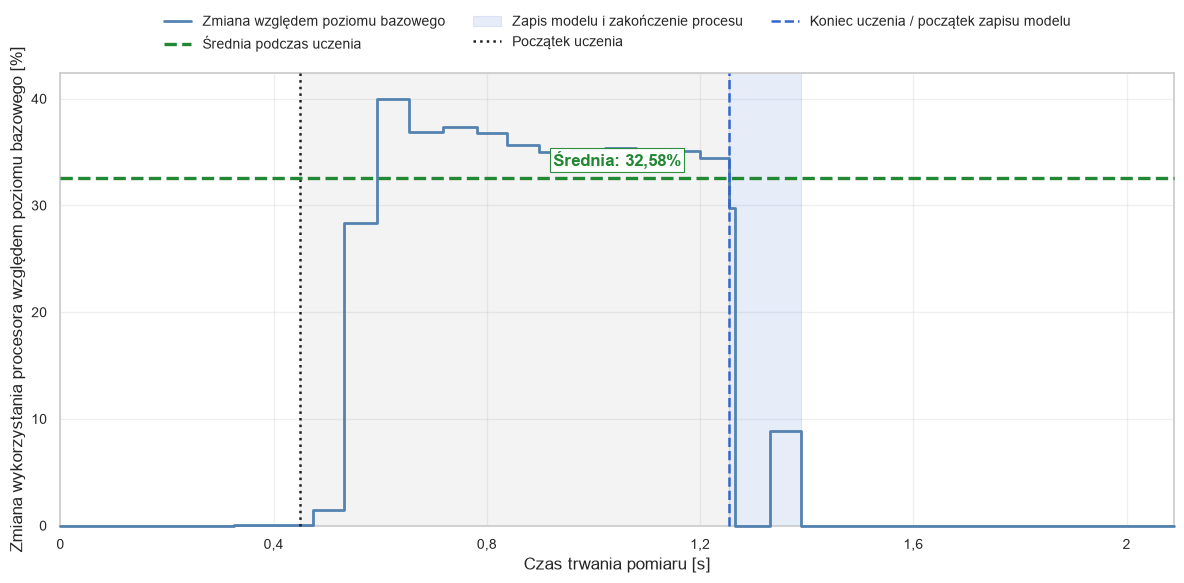

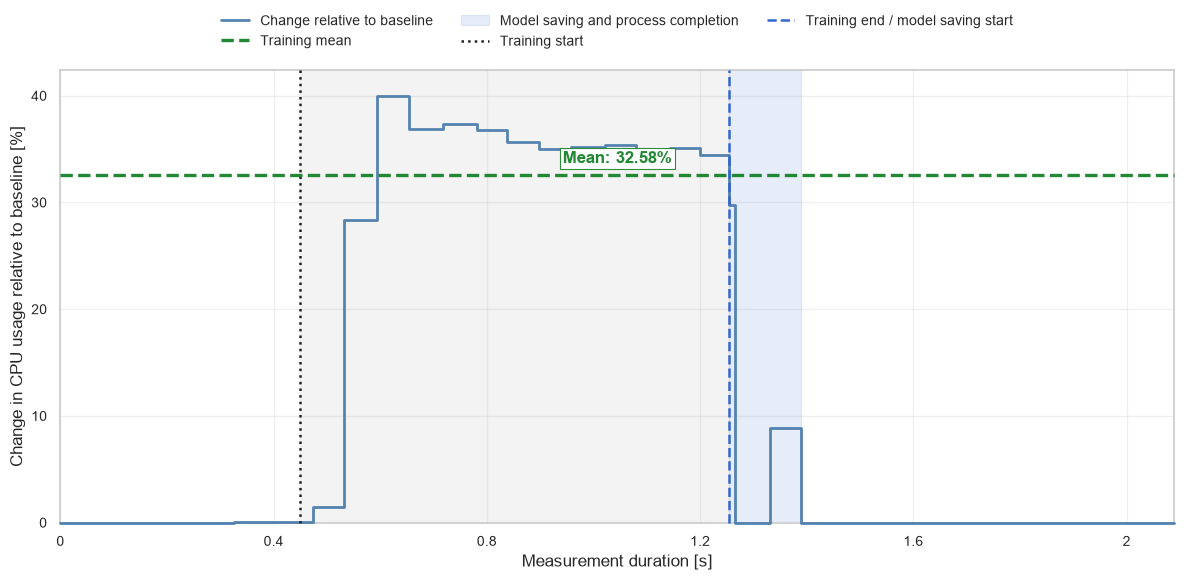

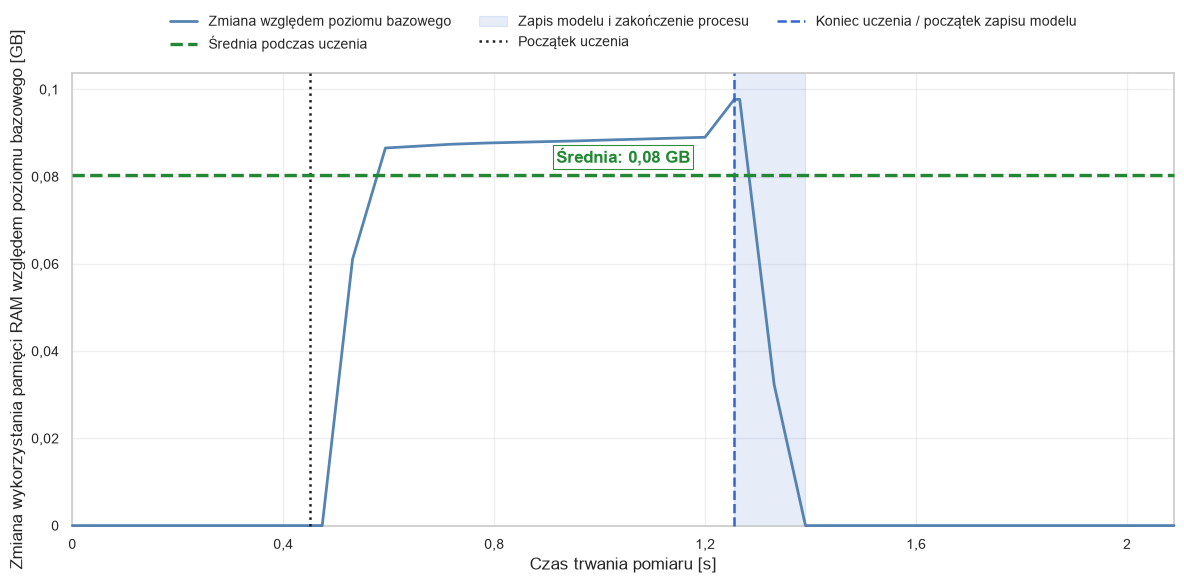

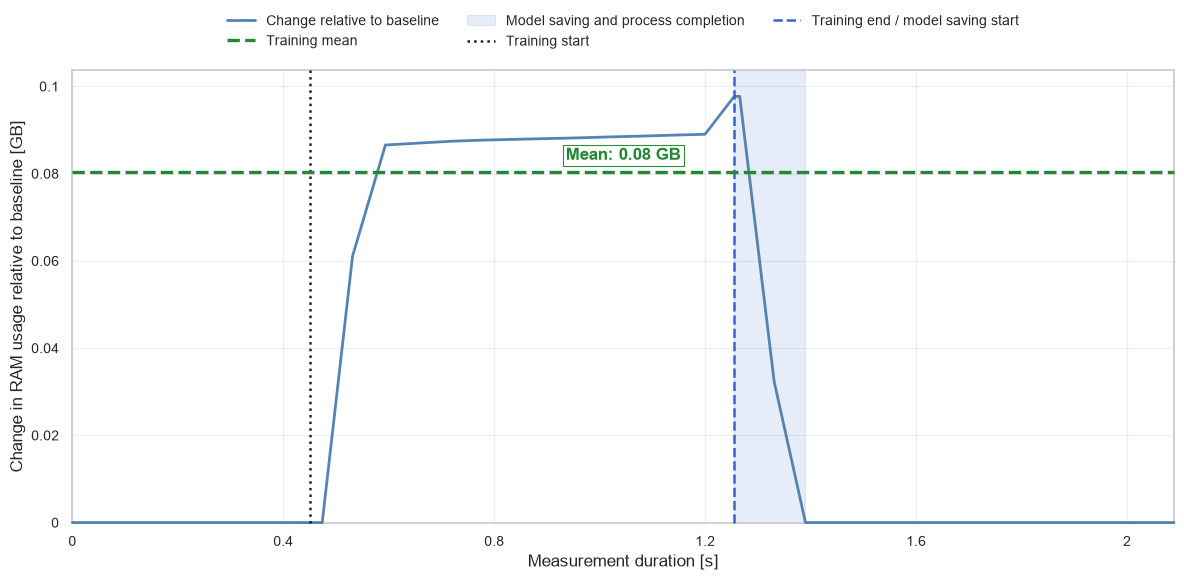

Zapisano ślad: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/resource_usage/xgboost_full.csv
Zapisano wykres CPU: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/xgboost/full/pl/xgboost_resource_usage_cpu.png
Zapisano wykres RAM: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/xgboost/full/pl/xgboost_resource_usage_ram.png


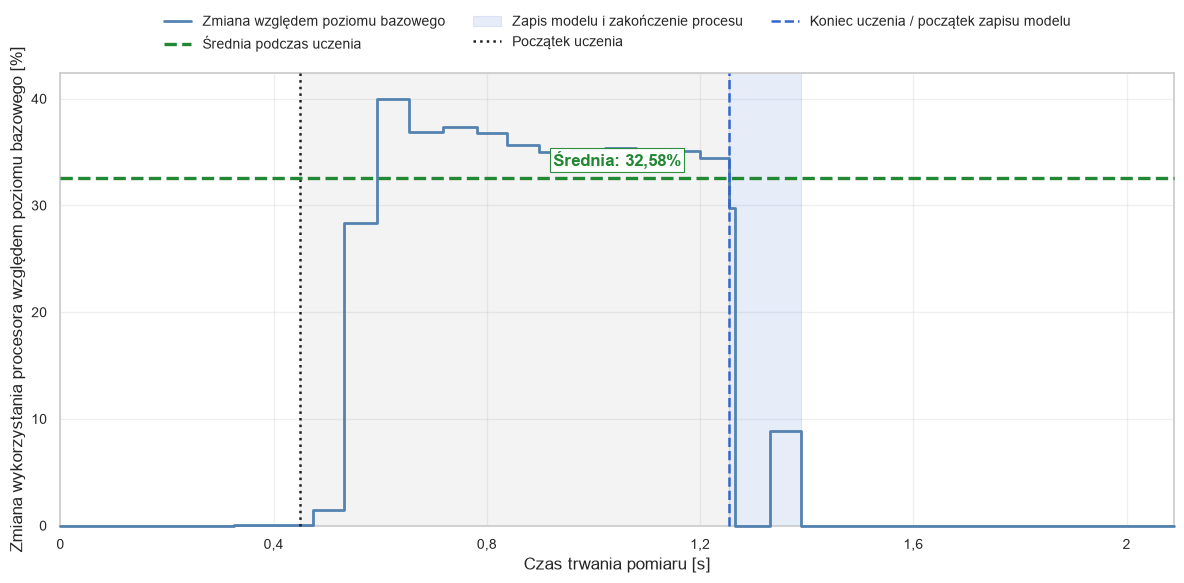

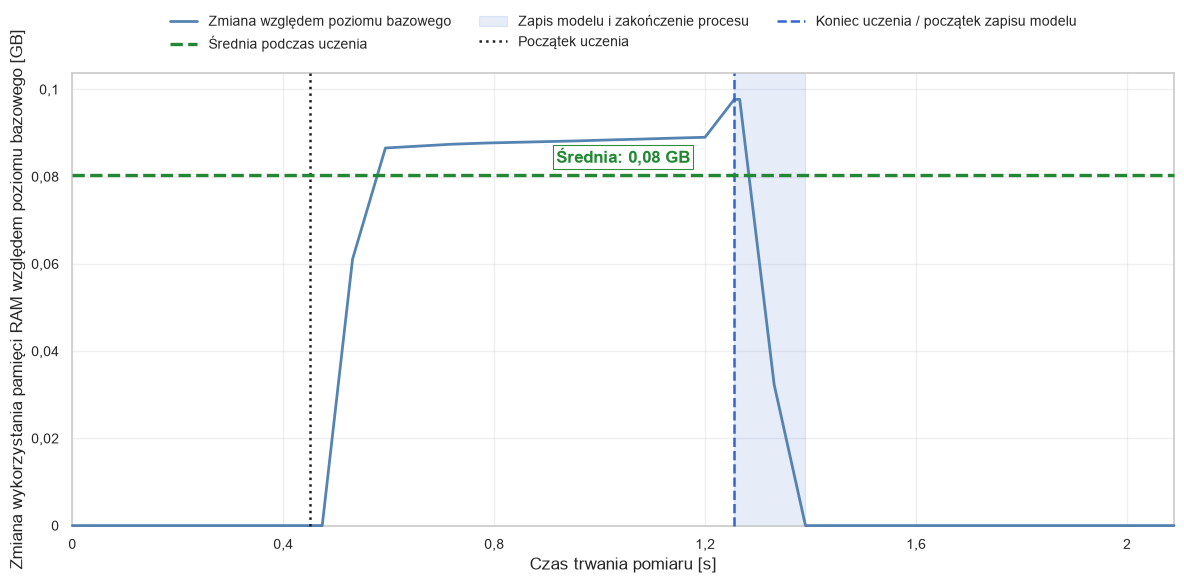

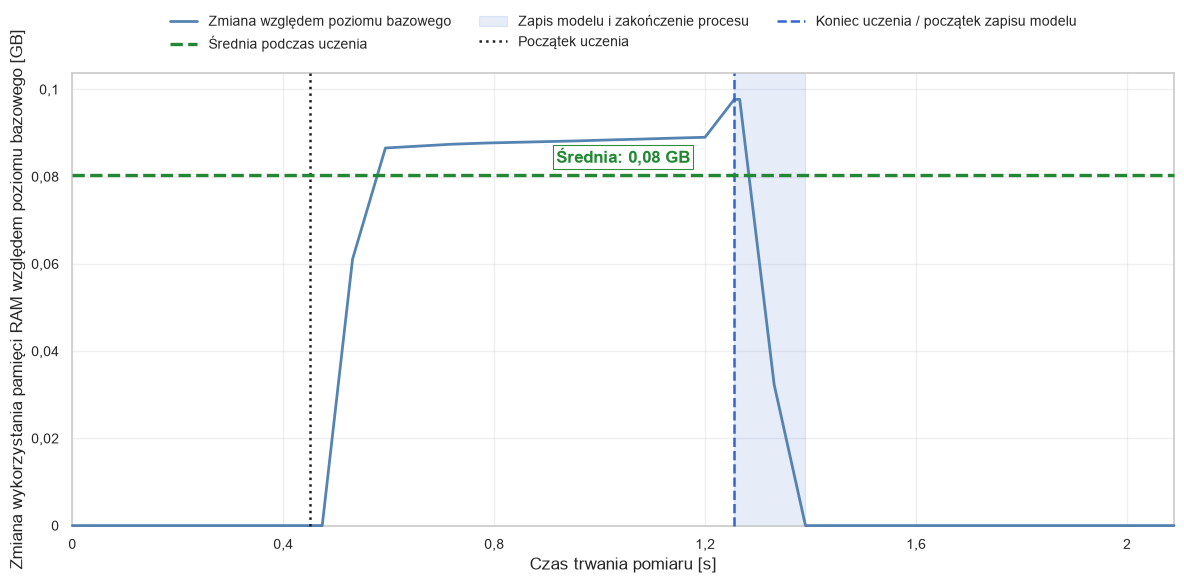

Poziom bazowy to mediana 8 próbek procesu izolowanego i jego procesów potomnych, zebranych bezpośrednio przed uczeniem (CPU: 0,02% łącznej mocy 11 rdzeni logicznych; RAM: 0,19 GB). Wykres przedstawia nieujemną różnicę: pomiar minus poziom bazowy.


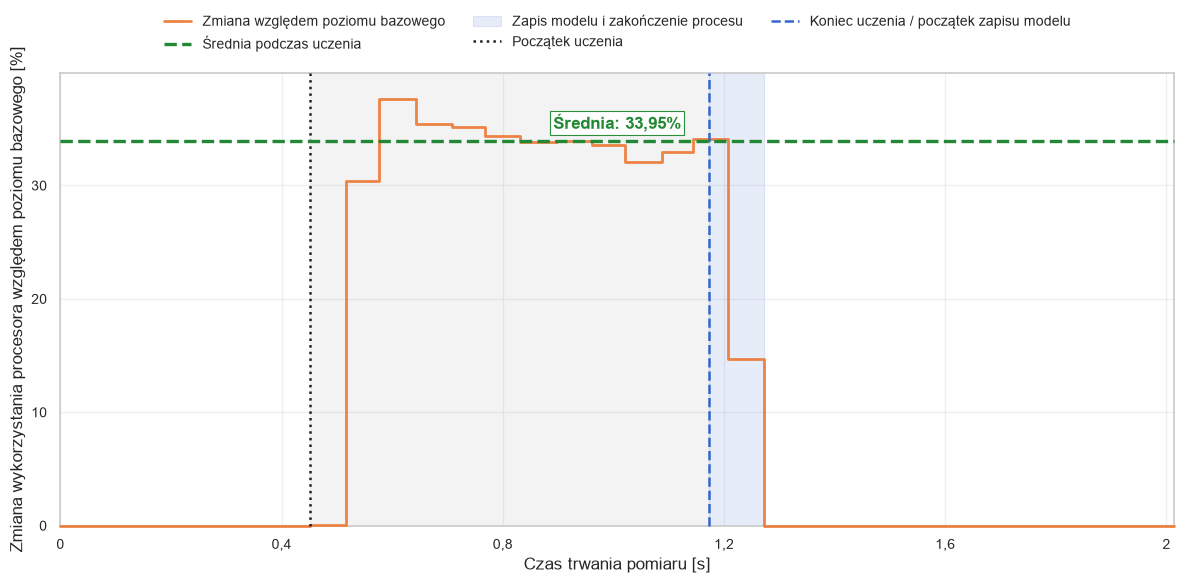

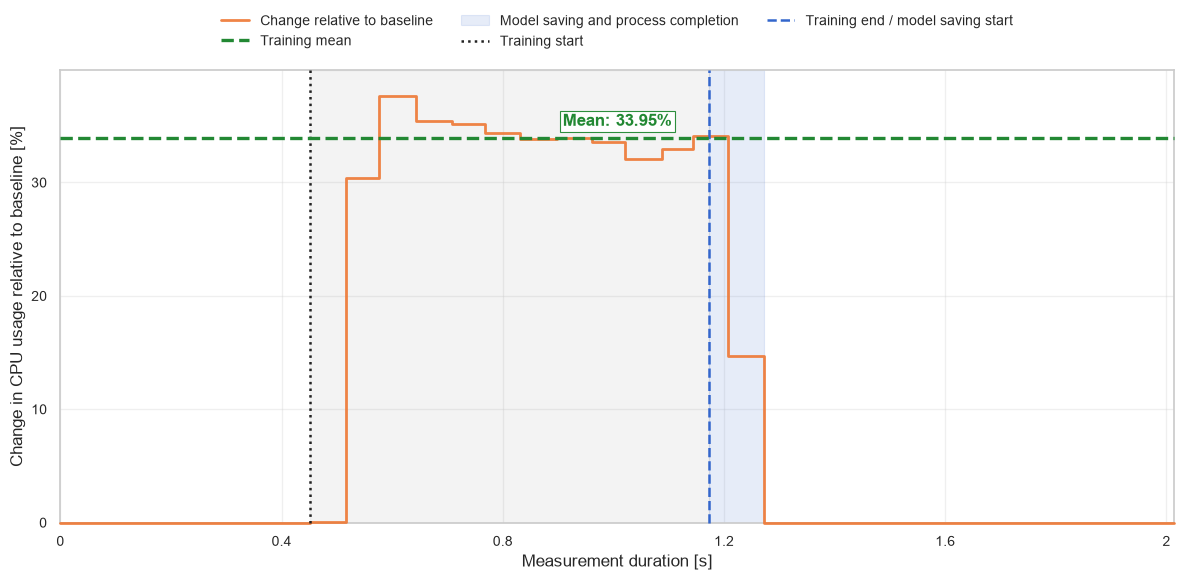

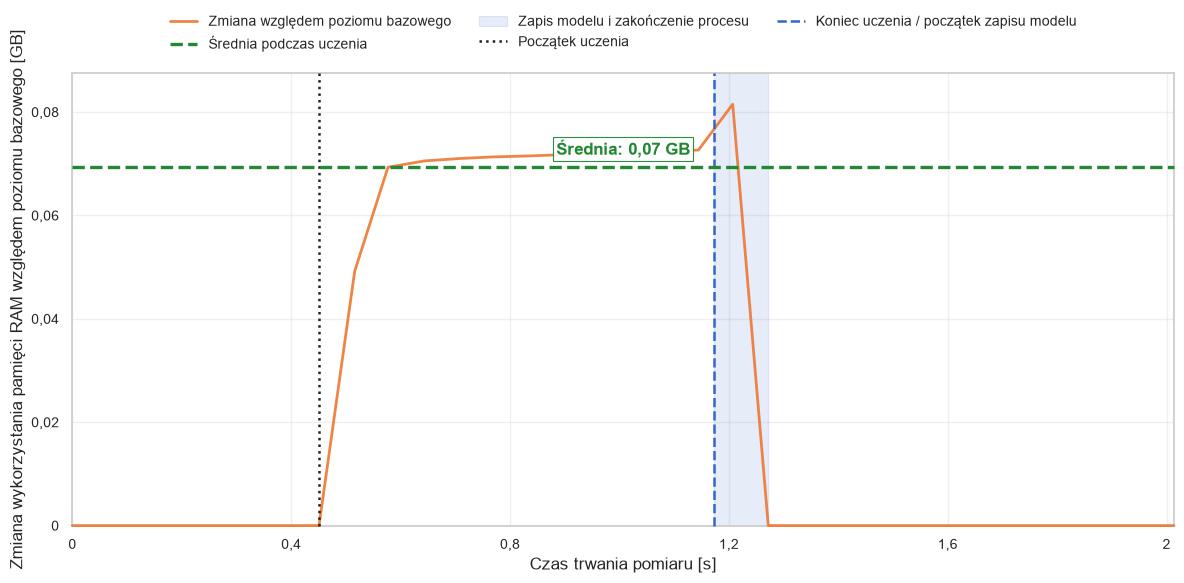

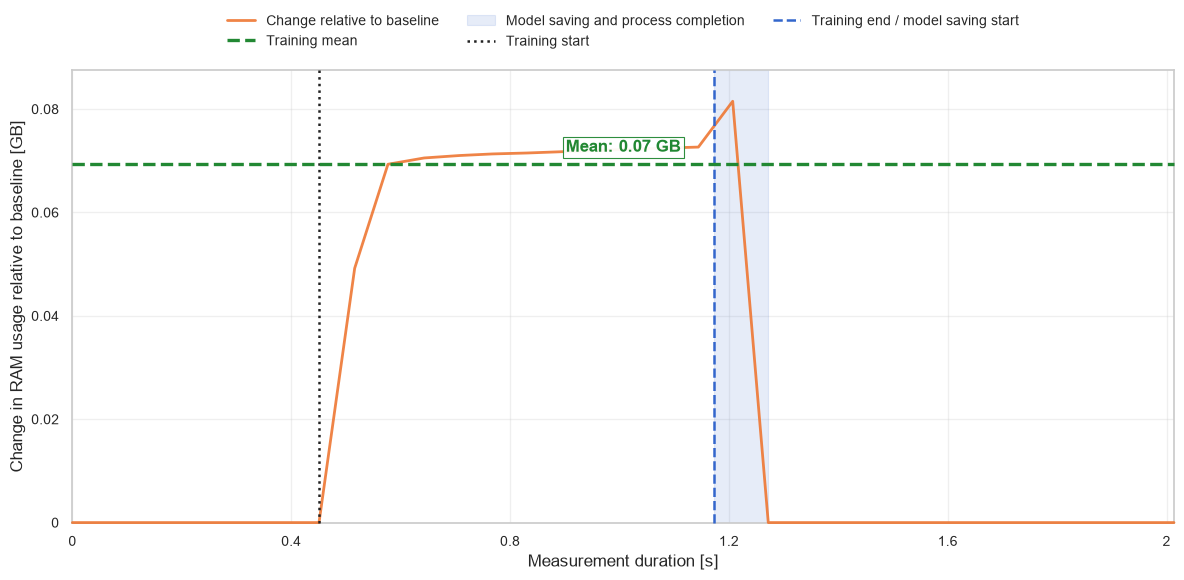

Zapisano ślad: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/resource_usage/xgboost_optimized.csv
Zapisano wykres CPU: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/xgboost/optimized/pl/xgboost_resource_usage_cpu.png
Zapisano wykres RAM: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/xgboost/optimized/pl/xgboost_resource_usage_ram.png


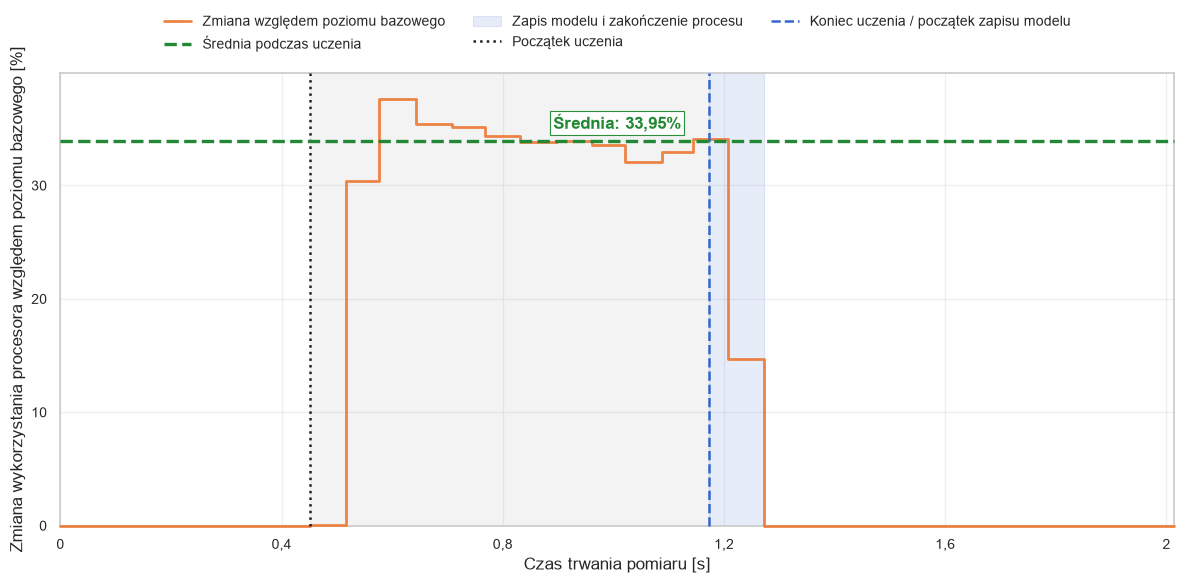

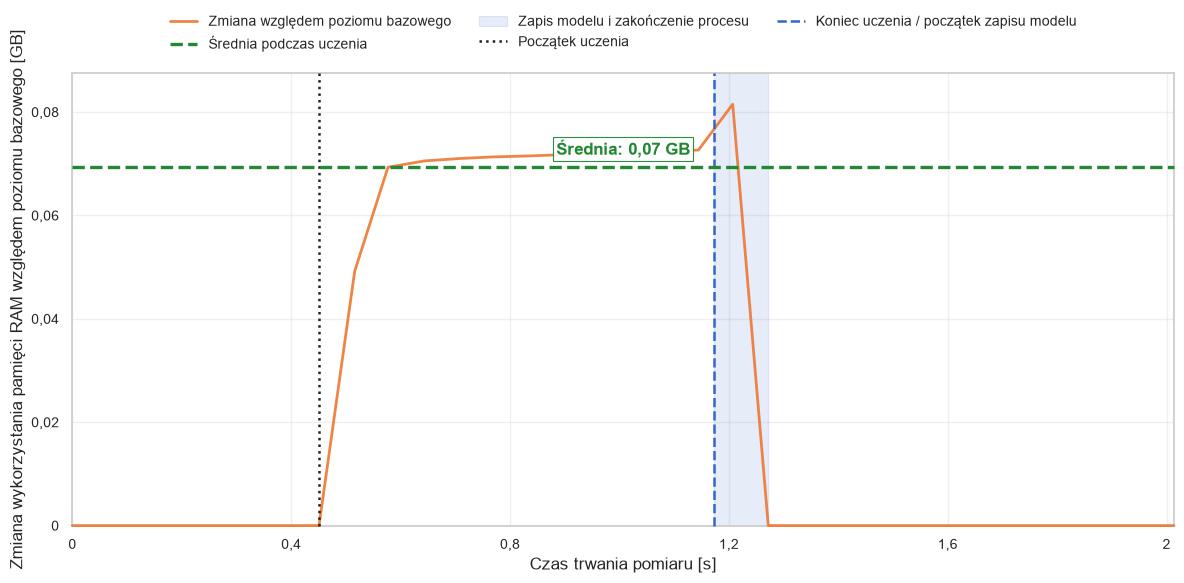

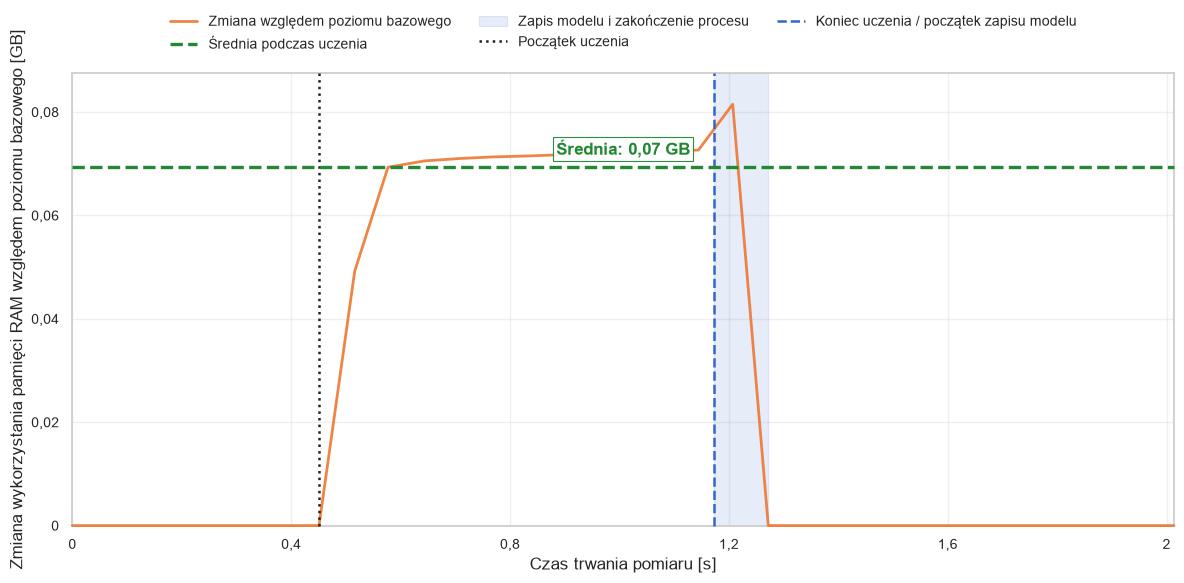

In [8]:
from IPython.display import display

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    monitor = results_for_datasets[dataset_name]['resource_monitor']
    stats = results_for_datasets[dataset_name]['resource_stats']
    print(resource_baseline_summary(monitor))
    trace_dir = backend_root.parent / 'results' / 'original' / 'resource_usage'
    trace_dir.mkdir(parents=True, exist_ok=True)
    trace_path = trace_dir / f"xgboost_{dataset_key(dataset_name)}.csv"
    monitor.save_phase_trace(trace_path)
    cpu_figure, ram_figure = plot_resource_usage_separate(monitor, stats, dataset_name, include_post_training=True)
    cpu_path = save_dataset_figure(cpu_figure, PLOTS_DIR, dataset_name, 'xgboost_resource_usage_cpu.png')
    ram_path = save_dataset_figure(ram_figure, PLOTS_DIR, dataset_name, 'xgboost_resource_usage_ram.png')
    print(f'Zapisano ślad: {trace_path}')
    print(f'Zapisano wykres CPU: {cpu_path}')
    print(f'Zapisano wykres RAM: {ram_path}')
    display(cpu_figure)
    display(ram_figure)
    plt.close(cpu_figure)
    plt.close(ram_figure)
    plt.show()


## 6. Porównanie wyników uczenia i testowania

Miary dla procesu uczenia obliczane są na zbiorze uczącym, a miary testowe na
niezależnym zbiorze testowym. Każda miara jest prezentowana na osobnym wykresie
i wykorzystuje wyniki uzyskane przez wytrenowany model, bez jego ponownego
uczenia na potrzeby wizualizacji.

Walidacja oznacza ocenę modelu na danych, które nie uczestniczyły w jego
dopasowaniu w danym przebiegu, ale nadal należą do części danych przeznaczonej
do opracowania modelu. Nie jest ona testem końcowym. Dla każdego rozmiaru
podzbioru uczącego linia uczenia i linia walidacji przedstawiają średnią z pięciu
przebiegów, a półprzezroczyste pasmo przedstawia jedno odchylenie standardowe.
Niezależny zbiór testowy nie uczestniczy w wyznaczaniu tych krzywych.
Oś pozioma nie przedstawia liczby próbek walidacyjnych ani testowych.



EWALUACJA MODELU - PEŁNY ZBIÓR



WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9714
  • Precyzja: 0.9705
  • Czułość: 0.9724
  • Miara F1 (F1-Score): 0.9715
  • AUC-ROC: 0.9953
  • Błąd uczenia: 0.0076
  • Błąd testowania: 0.0286


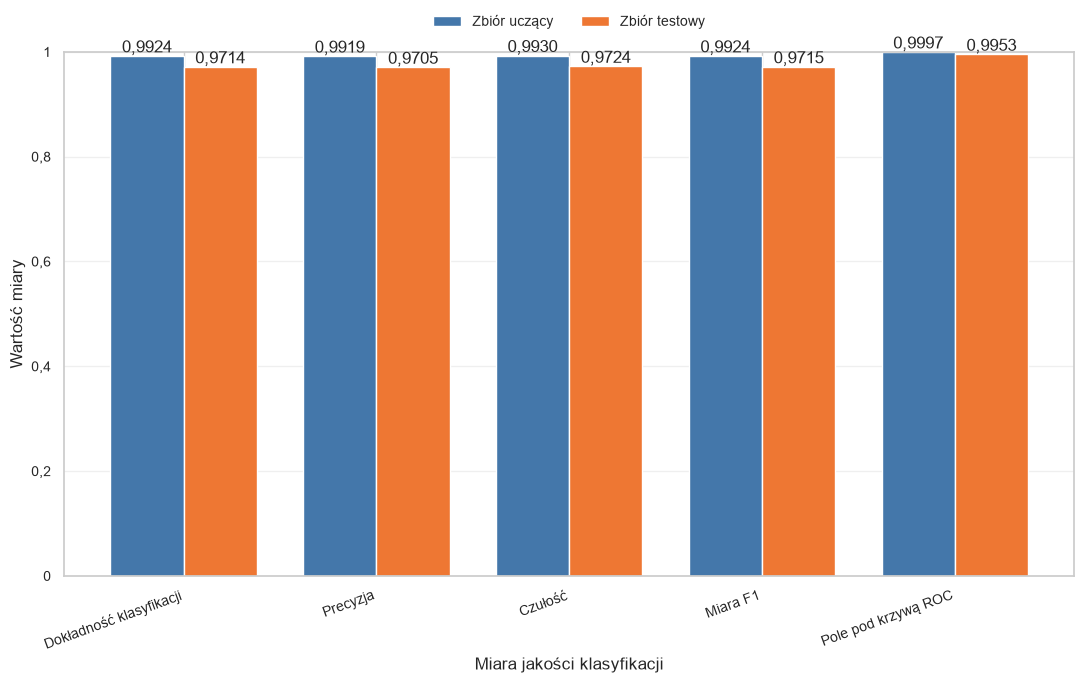

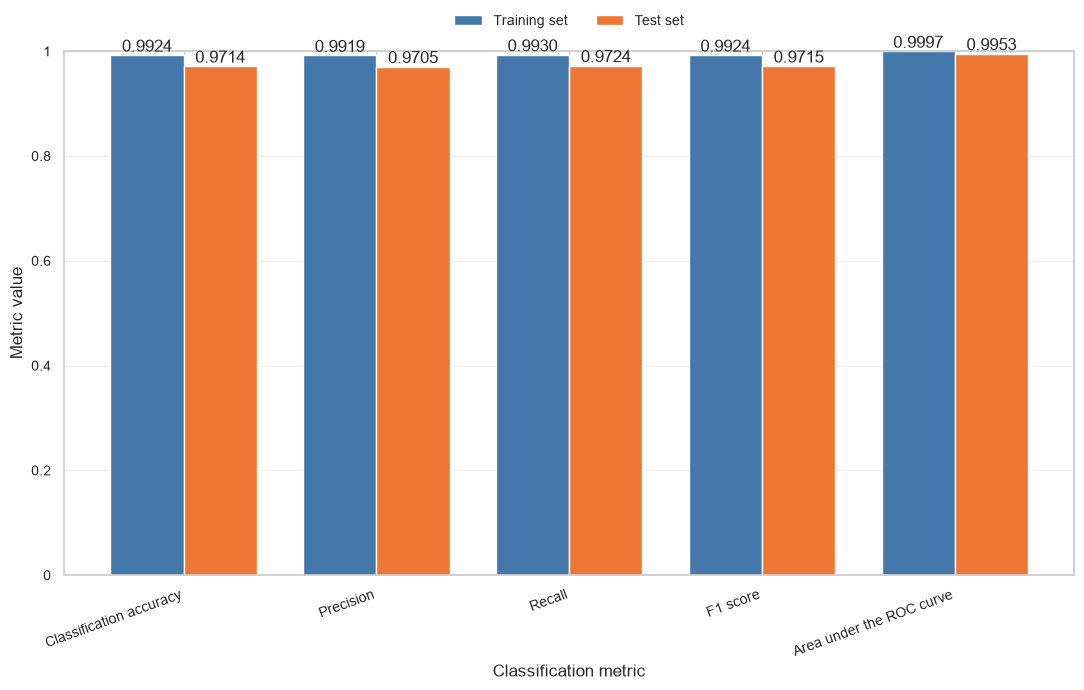

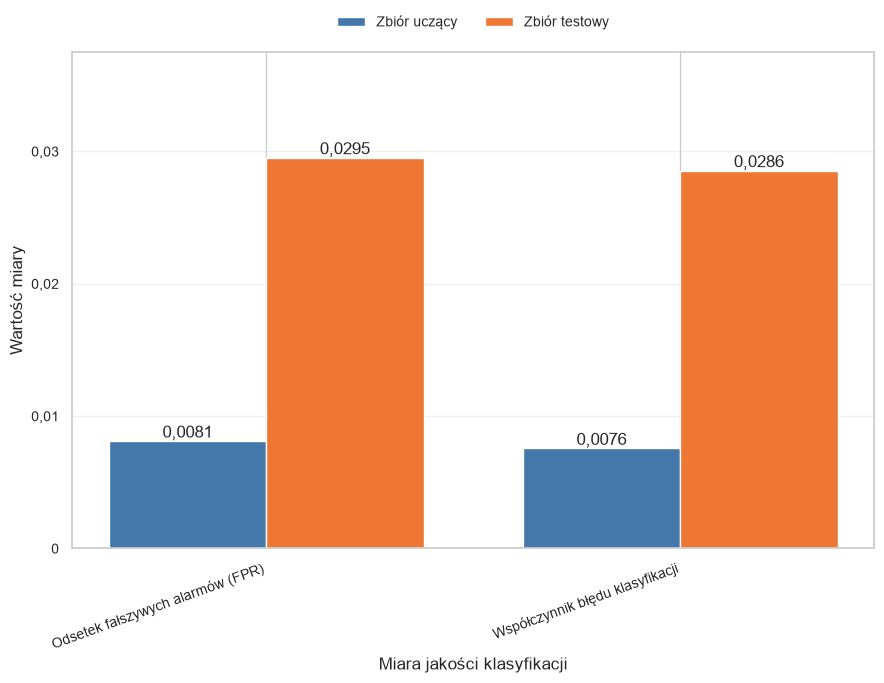

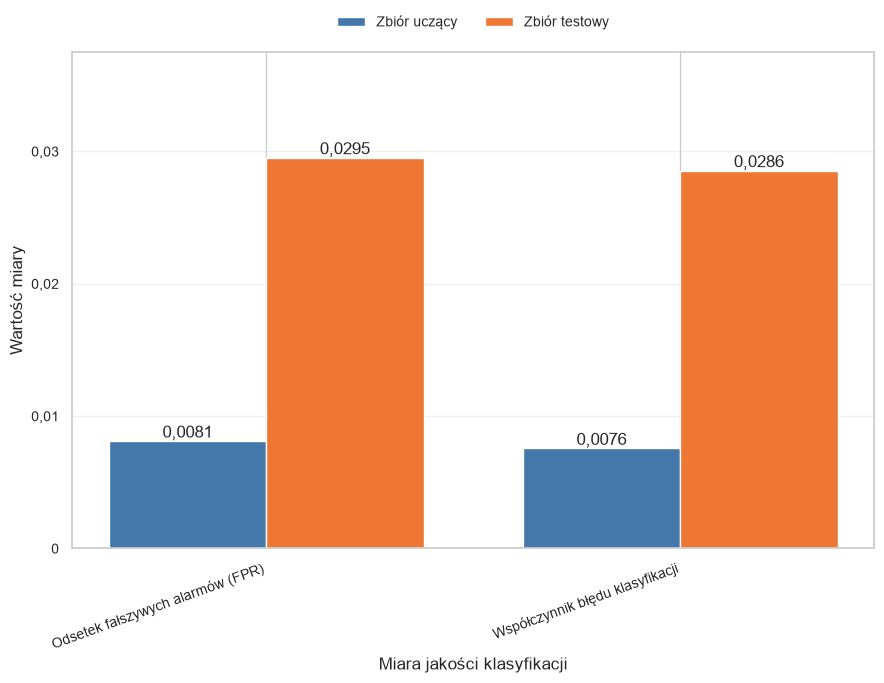

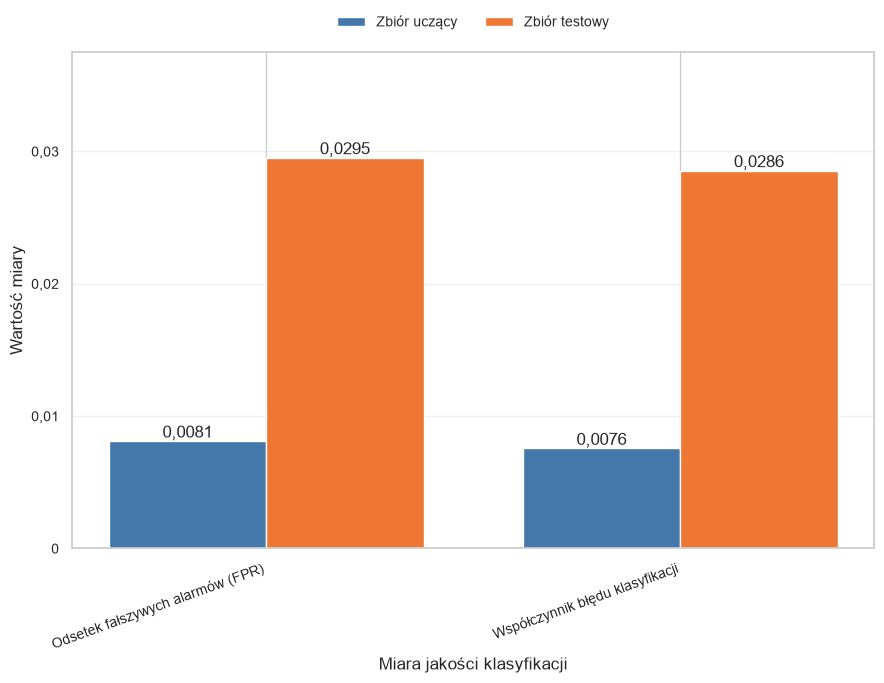

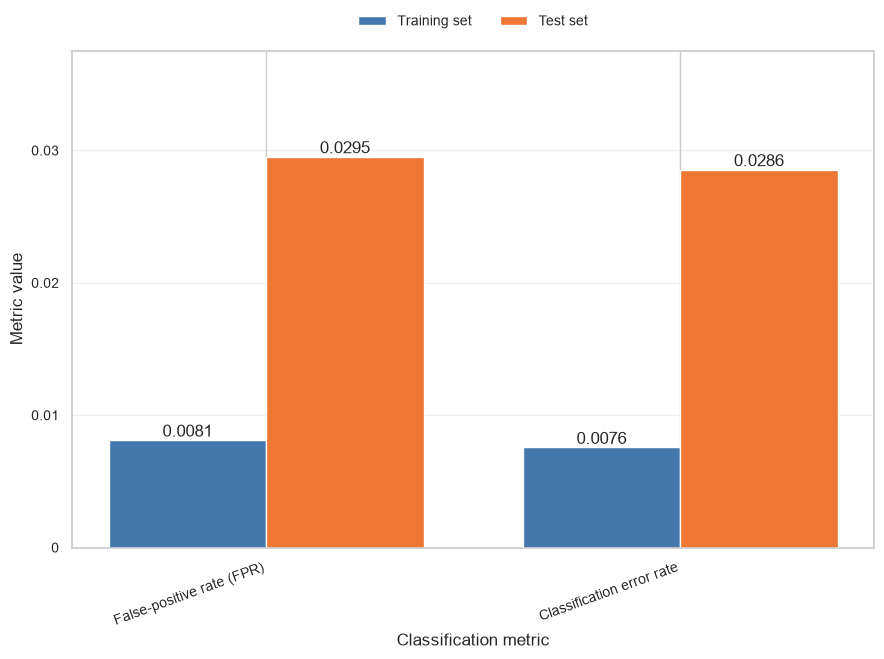


MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 5,949
  • Fałszywie pozytywne (FP): 181
  • Fałszywie negatywne (FN): 169
  • Prawdziwie pozytywne (TP): 5,960

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9948 ± 0.0005
  • Min: 0.9940
  • Max: 0.9956

EWALUACJA MODELU - ZOPTYMALIZOWANY ZBIÓR



WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9698
  • Precyzja: 0.9691
  • Czułość: 0.9705
  • Miara F1 (F1-Score): 0.9698
  • AUC-ROC: 0.9949
  • Błąd uczenia: 0.0069
  • Błąd testowania: 0.0302


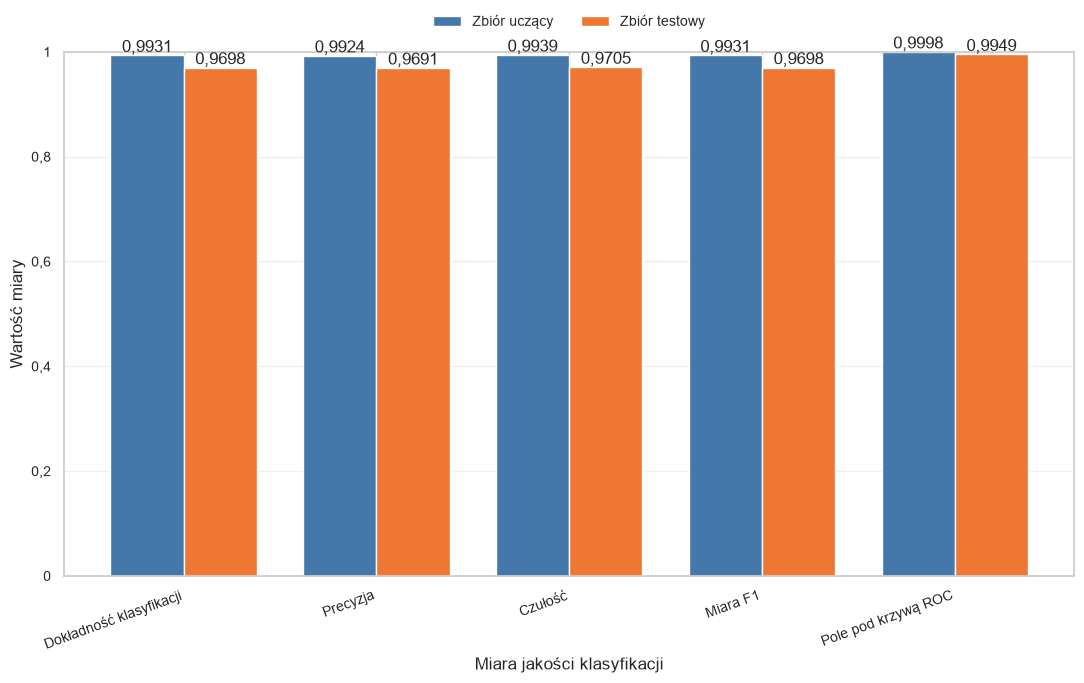

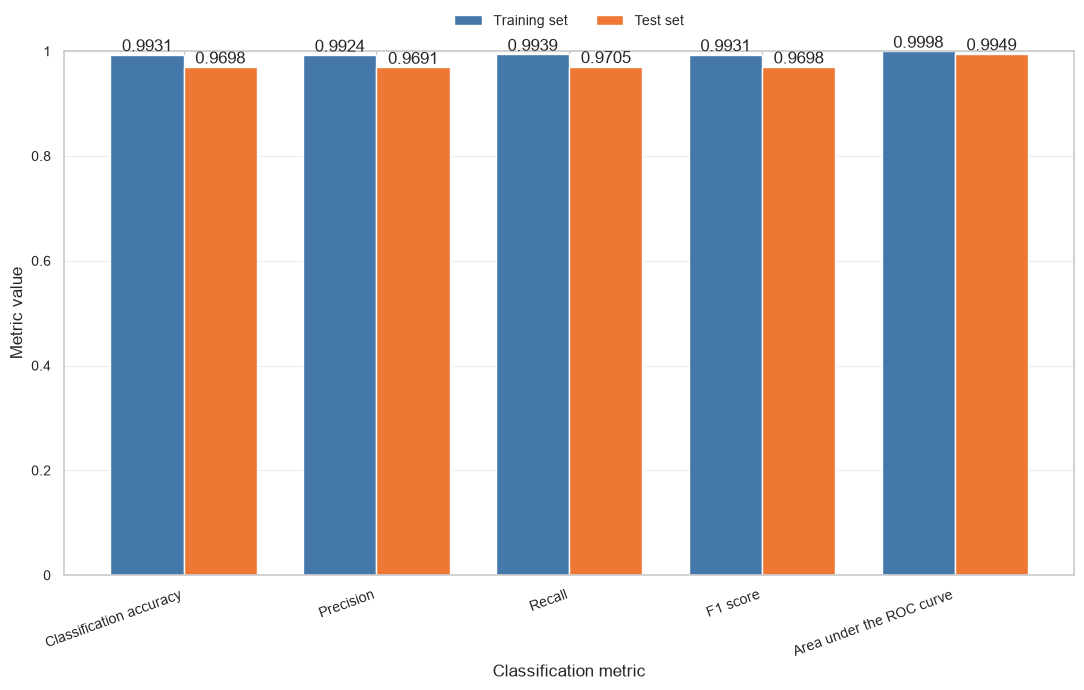

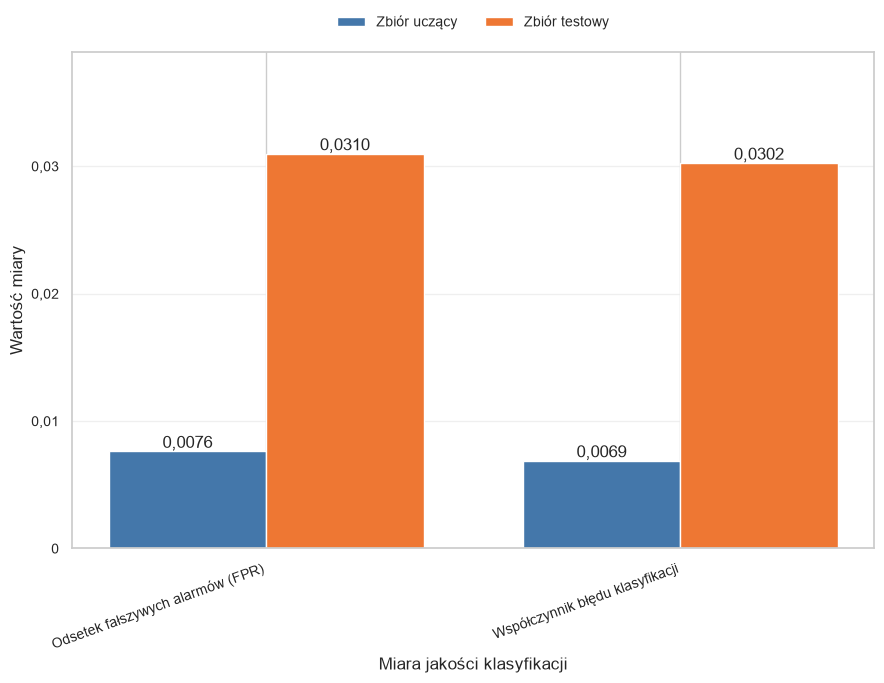

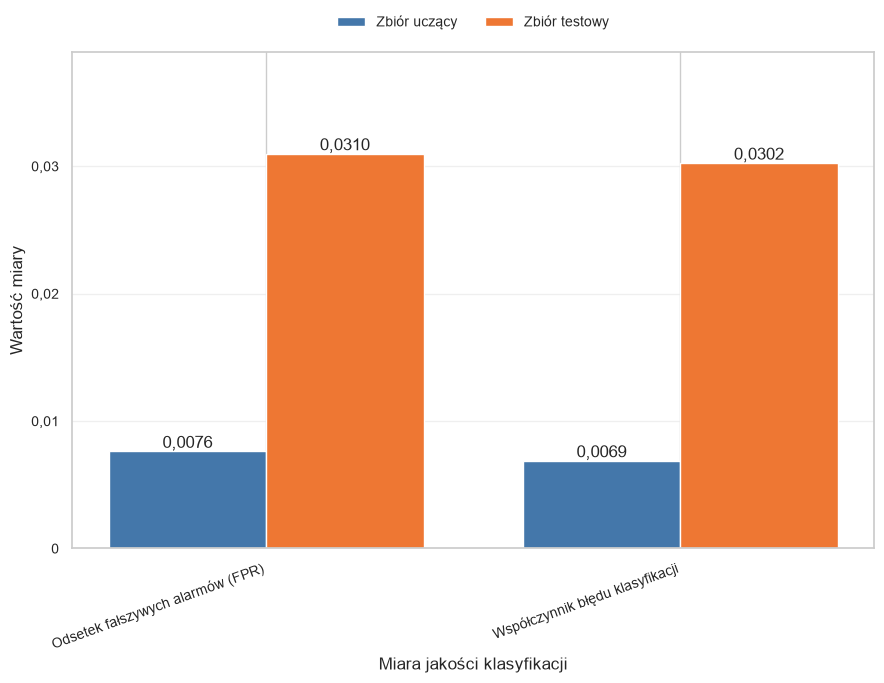

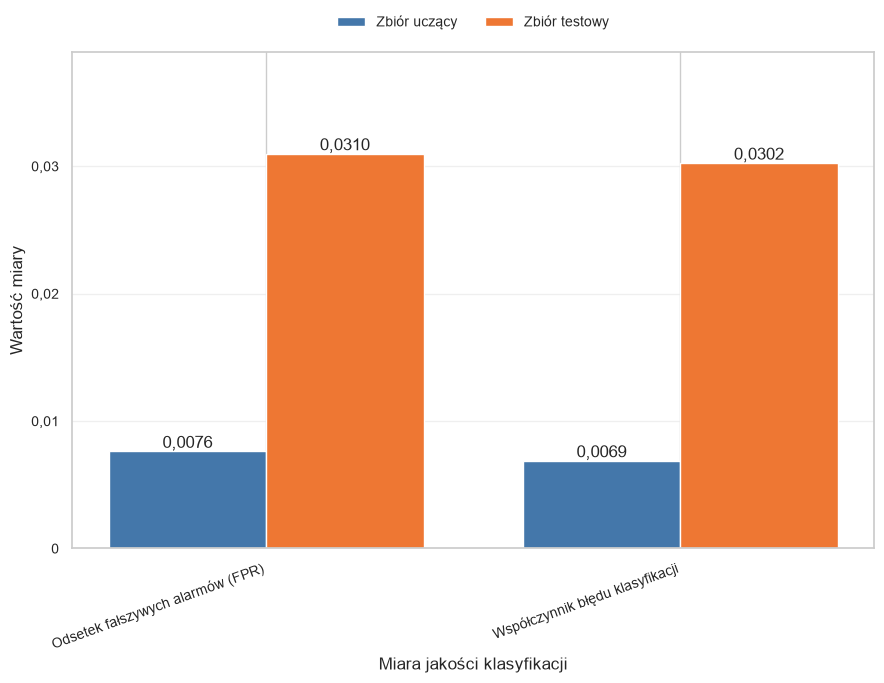

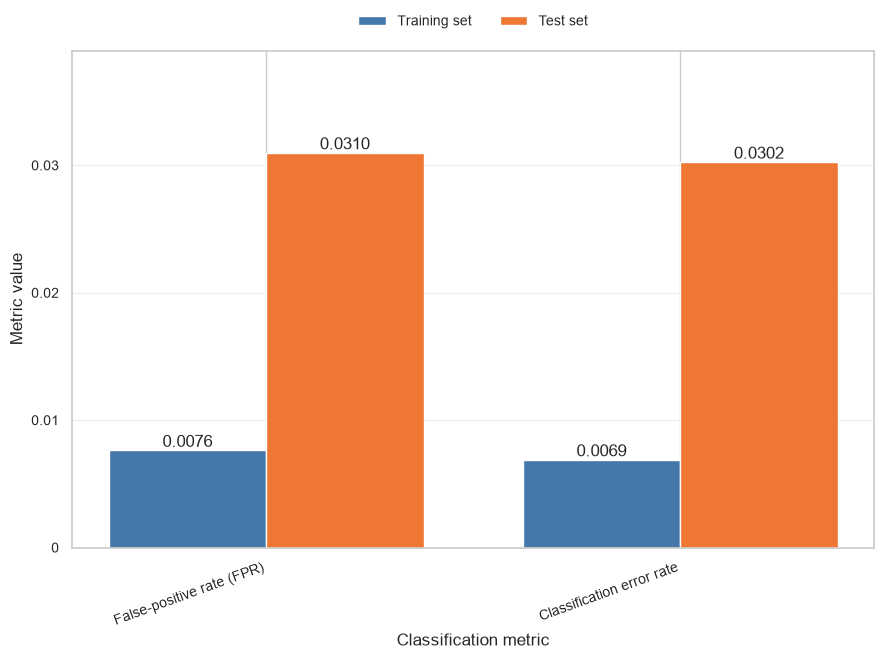


MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 5,911
  • Fałszywie pozytywne (FP): 189
  • Fałszywie negatywne (FN): 180
  • Prawdziwie pozytywne (TP): 5,919

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9948 ± 0.0004
  • Min: 0.9942
  • Max: 0.9954

PORÓWNANIE WYNIKÓW
Metryka                  Pełny zbiór Zoptymalizowany zbiór
--------------------------------------------------------------------------------
Accuracy                      0.9714          0.9698 (-0.0017)
Precision                     0.9705          0.9691 (-0.0015)
Recall                        0.9724          0.9705 (-0.0019)
F1                            0.9715          0.9698 (-0.0017)
Auc_roc                       0.9953          0.9949 (-0.0004)


In [9]:
evaluation_results = {}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{'='*80}")
    print(f"EWALUACJA MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    model = results_for_datasets[dataset_name]['model']
    X_train = results_for_datasets[dataset_name]['X_train']
    X_test = results_for_datasets[dataset_name]['X_test']
    y_train = results_for_datasets[dataset_name]['y_train']
    y_test = results_for_datasets[dataset_name]['y_test']

    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    y_train_pred = model.predict(X_train)
    y_train_proba = model.predict_proba(X_train)[:, 1]

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    train_cm = confusion_matrix(y_train, y_train_pred)
    train_tn, train_fp, train_fn, train_tp = train_cm.ravel()

    accuracy = accuracy_score(y_test, y_pred)
    train_accuracy = accuracy_score(y_train, y_train_pred)
    train_error_rate = 1.0 - accuracy_score(y_train, y_train_pred)
    test_error_rate = 1.0 - accuracy
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    train_precision = precision_score(y_train, y_train_pred, zero_division=0)
    train_recall = recall_score(y_train, y_train_pred, zero_division=0)
    train_f1 = f1_score(y_train, y_train_pred, zero_division=0)
    false_positive_rate = fp / (fp + tn) if (fp + tn) else 0.0
    train_false_positive_rate = train_fp / (train_fp + train_tn) if (train_fp + train_tn) else 0.0
    auc_roc = roc_auc_score(y_test, y_pred_proba)
    train_auc_roc = roc_auc_score(y_train, y_train_proba)
    train_bce = log_loss(y_train, y_train_proba)
    test_bce = log_loss(y_test, y_pred_proba)

    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')

    evaluation_results[dataset_name] = {
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba,
        'confusion_matrix': cm,
        'accuracy': accuracy,
        'train_accuracy': train_accuracy,
        'train_error_rate': train_error_rate,
        'test_error_rate': test_error_rate,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'train_precision': train_precision,
        'train_recall': train_recall,
        'train_f1': train_f1,
        'false_positive_rate': false_positive_rate,
        'train_false_positive_rate': train_false_positive_rate,
        'auc_roc': auc_roc,
        'train_auc_roc': train_auc_roc,
        'train_bce': train_bce,
        'test_bce': test_bce,
        'cv_scores': cv_scores,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std()
    }

    print(f"\nWYNIKI NA ZBIORZE TESTOWYM:")
    print(f"  • Dokładność (Accuracy): {accuracy:.4f}")
    print(f"  • Precyzja: {precision:.4f}")
    print(f"  • Czułość: {recall:.4f}")
    print(f"  • Miara F1 (F1-Score): {f1:.4f}")
    print(f"  • AUC-ROC: {auc_roc:.4f}")
    print(f"  • Błąd uczenia: {train_error_rate:.4f}")
    print(f"  • Błąd testowania: {test_error_rate:.4f}")

    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'xgboost_final_error_rate.png'
    )

    train_metrics, test_metrics = classification_metric_sets(
        evaluation_results[dataset_name]
    )
    metric_figures = plot_final_train_test_metric_groups(
        train_metrics, test_metrics
    )
    for group_name, metric_figure in metric_figures.items():
        save_dataset_figure(
            metric_figure, PLOTS_DIR, dataset_name,
            f'xgboost_metrics_{group_name}.png',
        )
        plt.show()

    print(f"\nMACIERZ POMYŁEK:")
    print(f"  • Prawdziwie negatywne (TN): {tn:,}")
    print(f"  • Fałszywie pozytywne (FP): {fp:,}")
    print(f"  • Fałszywie negatywne (FN): {fn:,}")
    print(f"  • Prawdziwie pozytywne (TP): {tp:,}")

    print(f"\nPIĘCIOKROTNA WALIDACJA KRZYŻOWA:")
    print(f"  • Średni wynik ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  • Min: {cv_scores.min():.4f}")
    print(f"  • Max: {cv_scores.max():.4f}")

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW")
print(f"{'='*80}")
print(f"{'Metryka':<20} {'Pełny zbiór':>15} {'Zoptymalizowany zbiór':>20}")
print(f"{'-'*80}")
for metric in ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']:
    full_val = evaluation_results['Pełny zbiór'][metric]
    opt_val = evaluation_results['Zoptymalizowany zbiór'][metric]
    diff = opt_val - full_val
    diff_str = f"({diff:+.4f})" if diff != 0 else ""
    print(f"{metric.capitalize():<20} {full_val:>15.4f} {opt_val:>15.4f} {diff_str:>5}")

## 7. Wizualizacja kompleksowa i krzywa uczenia


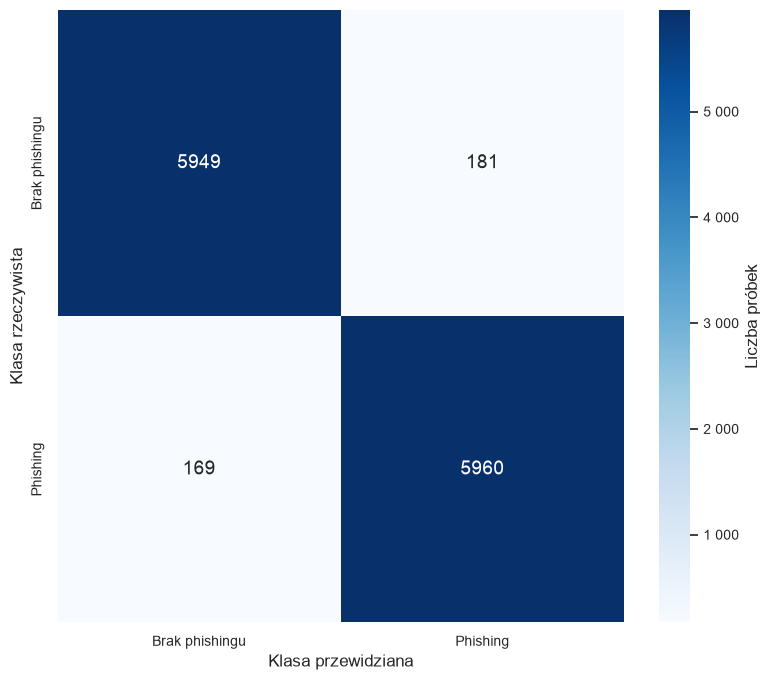

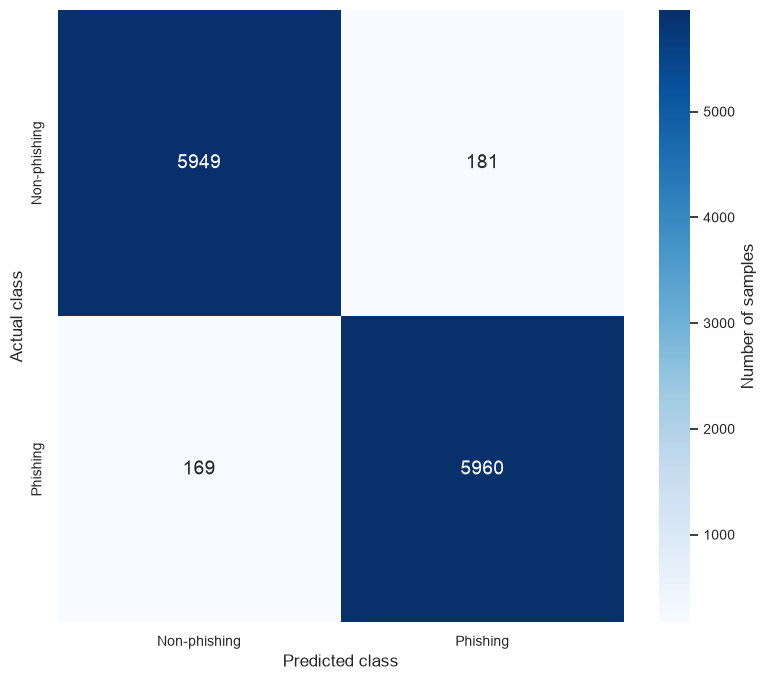

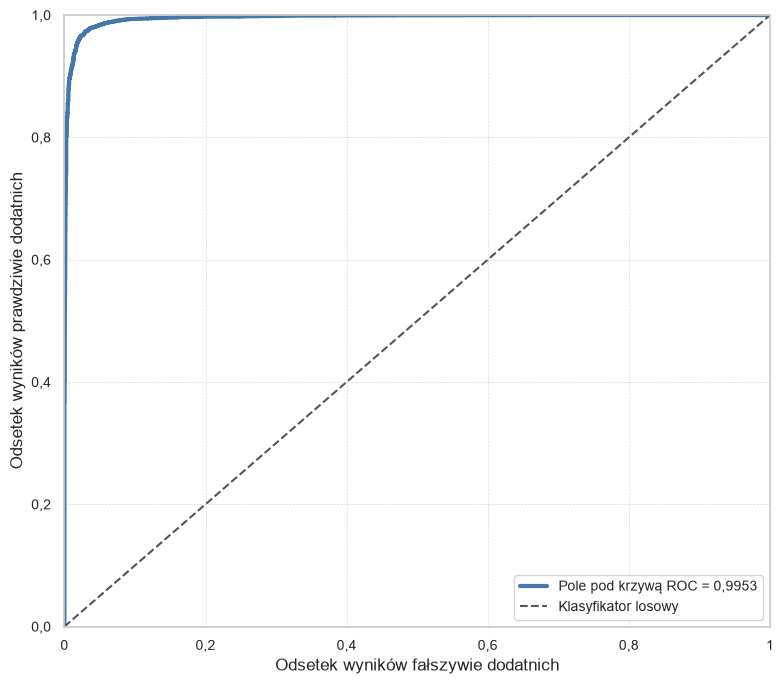

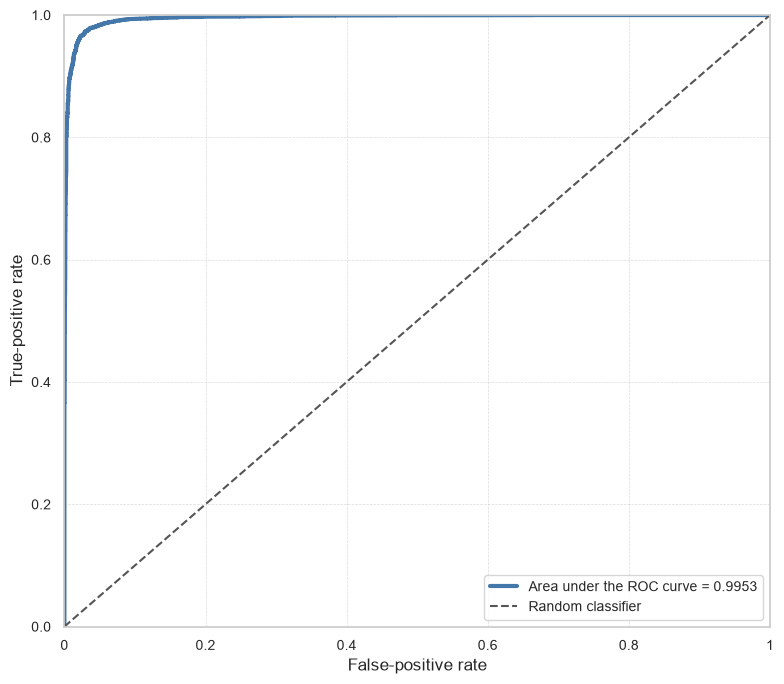

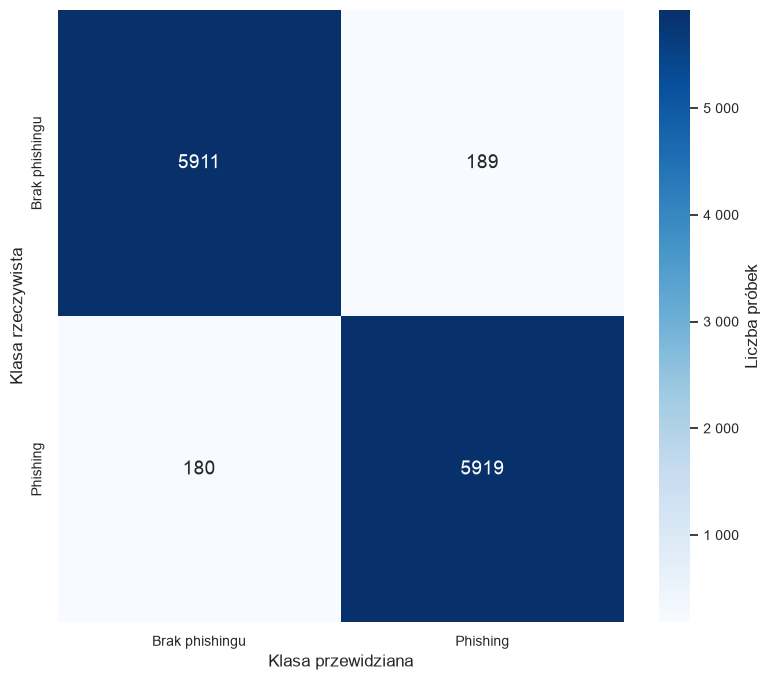

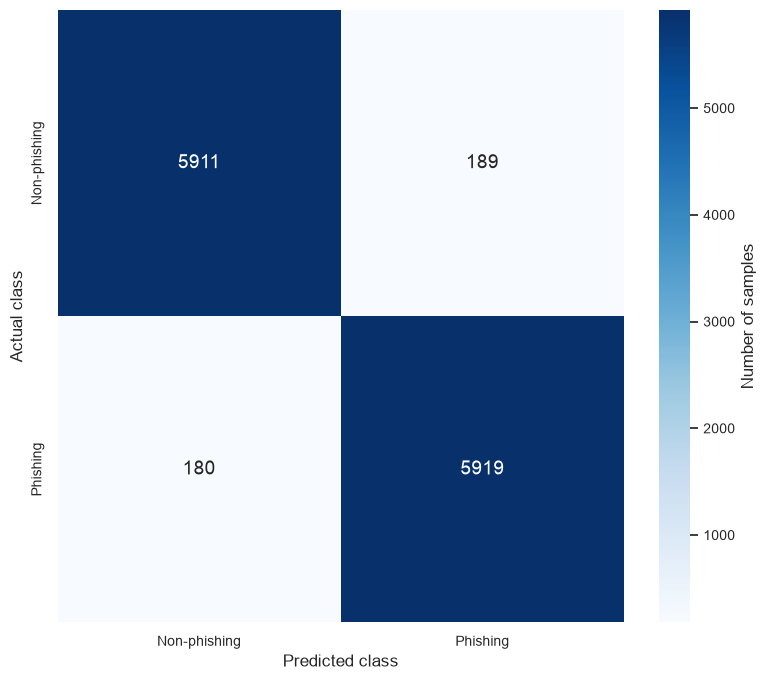

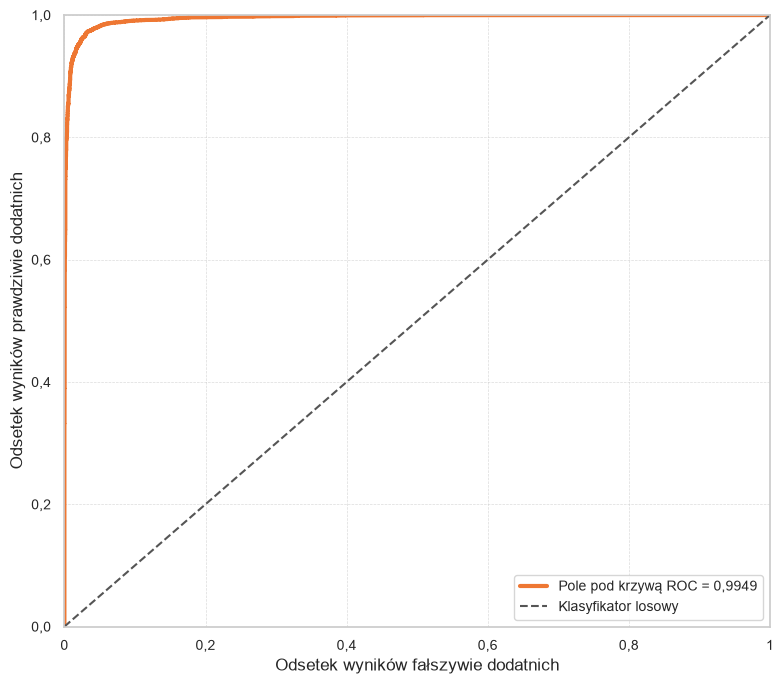

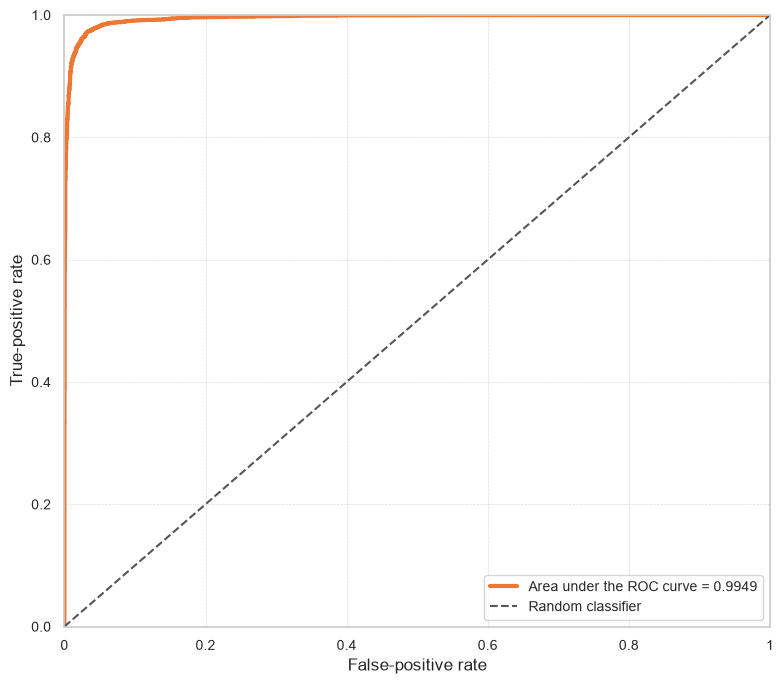

In [10]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    evaluation = evaluation_results[dataset_name]

    confusion_figure, _ = plot_confusion_matrix(
        evaluation['confusion_matrix'], dataset_name,
    )
    save_dataset_figure(
        confusion_figure, PLOTS_DIR, dataset_name, 'xgboost_confusion_matrix.png'
    )
    plt.show()

    roc_figure, _ = plot_roc_curve(
        results_for_datasets[dataset_name]['y_test'], evaluation['y_pred_proba'], evaluation['auc_roc'], dataset_name,
    )
    save_dataset_figure(
        roc_figure, PLOTS_DIR, dataset_name, 'xgboost_roc_curve.png'
    )
    plt.show()


## 7.1. Porównanie metryk w postaci wykresów słupkowych


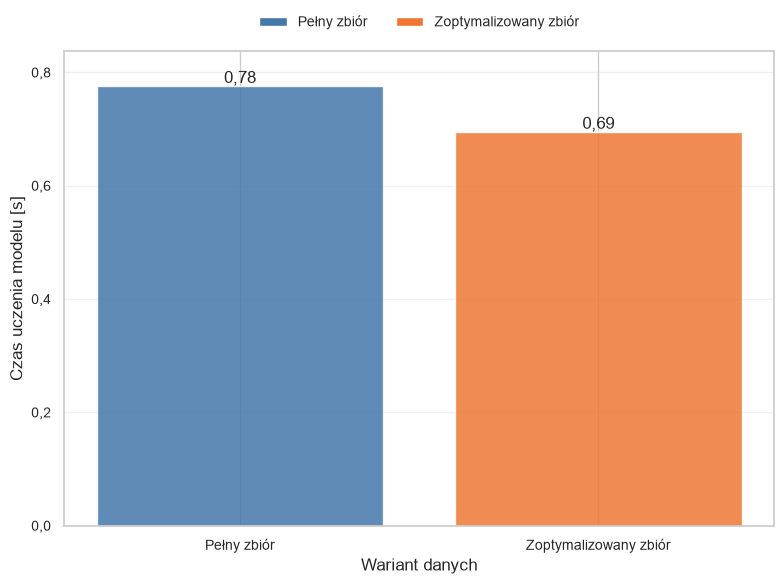

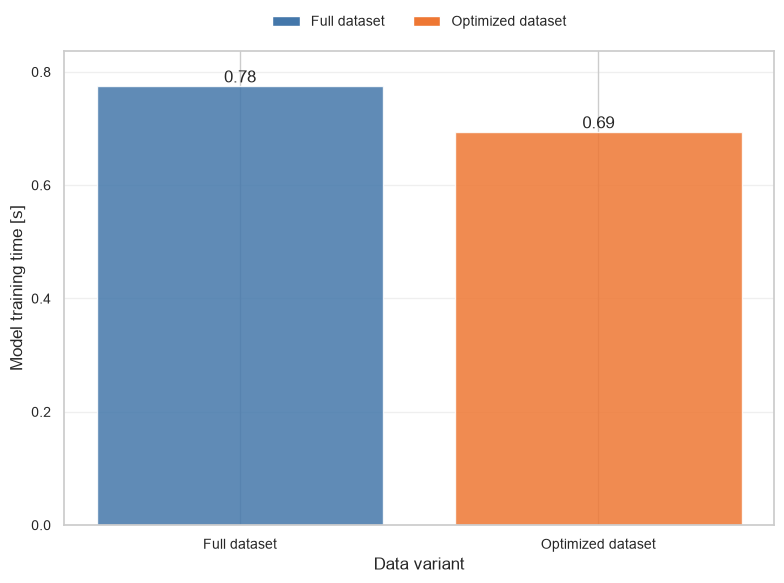

,Wariant danych,Liczba cech,Redukcja liczby cech,Redukcja [%]
0,Pełny zbiór,111,0,0.00
1,Zoptymalizowany zbiór,74,37,33.33


In [11]:
training_times = {}
feature_counts = {}
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    training_times[dataset_name] = float(results_for_datasets[dataset_name]['training_time'])
    feature_counts[dataset_name] = int(len(data_splits[dataset_name]['X'].columns))
    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'xgboost_training_time.png'
    )
    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'xgboost_feature_count.png'
    )

time_figure, _ = plot_training_time_comparison(training_times)
save_comparison_figure(
    time_figure, PLOTS_DIR / 'xgboost_training_time_comparison.png'
)
plt.show()

feature_count_rows = feature_count_comparison_rows(
    feature_counts['Pełny zbiór'],
    feature_counts['Zoptymalizowany zbiór'],
)
display(pd.DataFrame(feature_count_rows))


## 7.1a. Wizualizacja przykładowego drzewa z modelu XGBoost


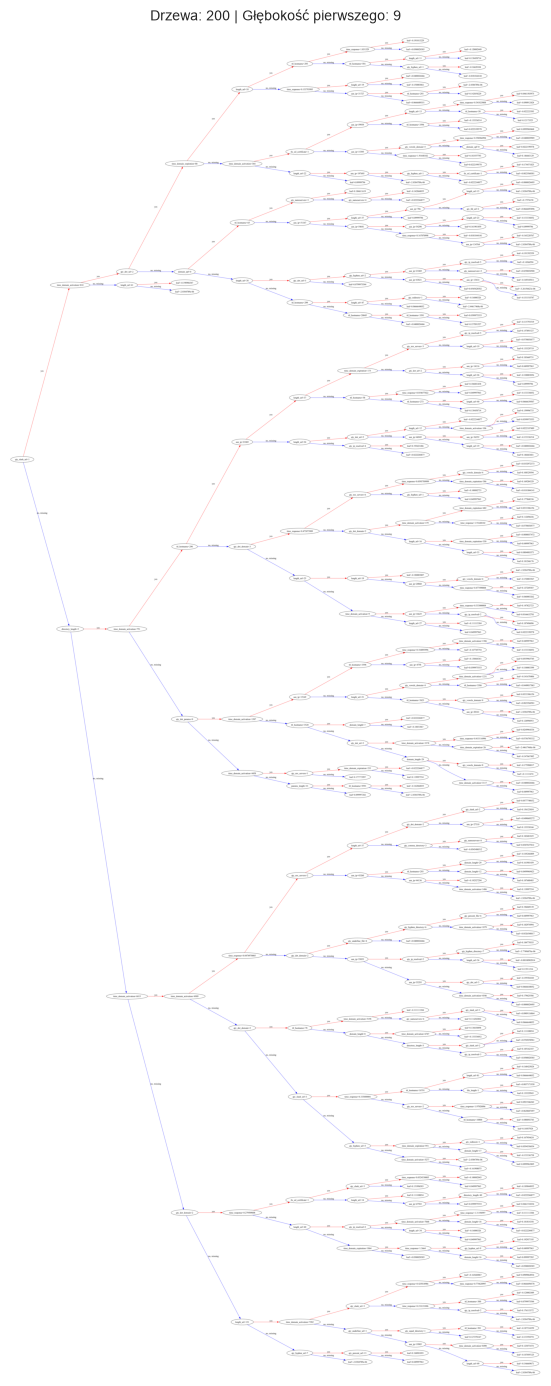

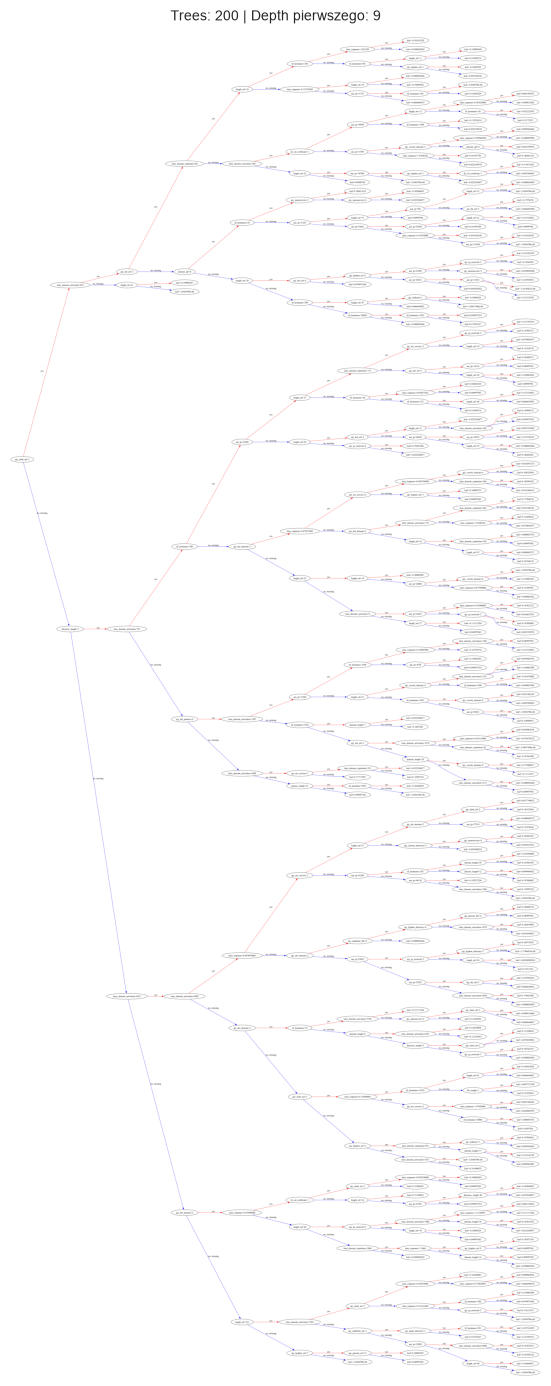

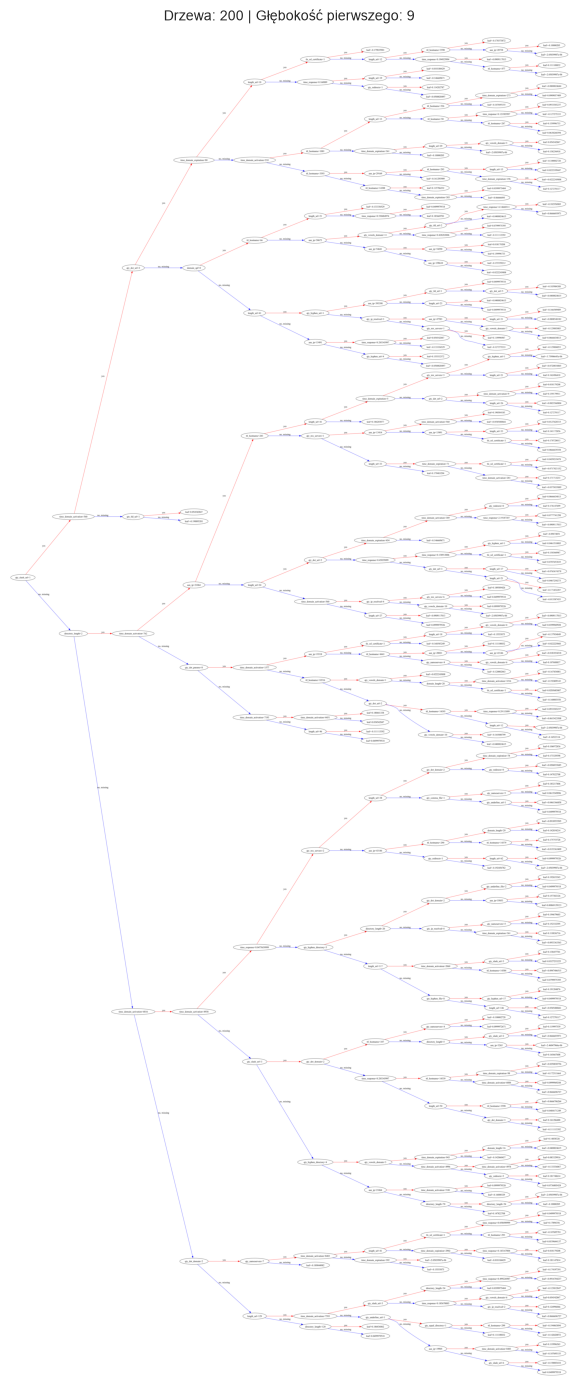

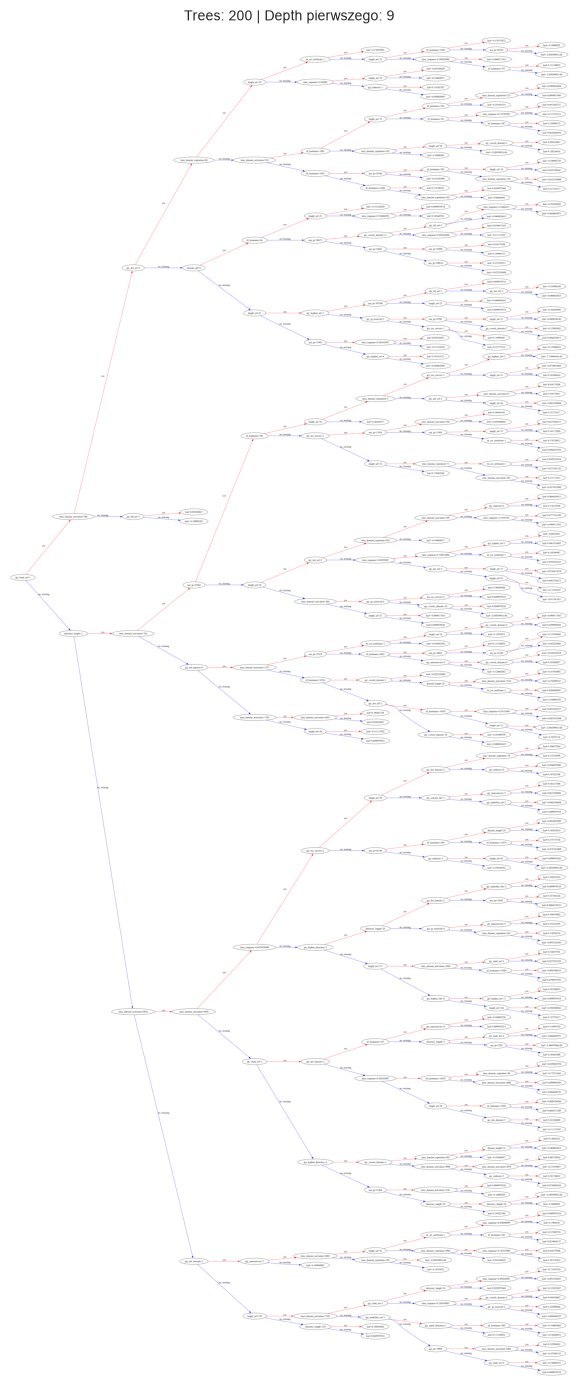

STATYSTYKI MODELI XGBOOST
Pełny zbiór: drzewa=200, parametry={'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 9, 'min_child_weight': 1, 'n_estimators': 200, 'scale_pos_weight': np.float64(1.0), 'subsample': 1.0}
Zoptymalizowany zbiór: drzewa=200, parametry={'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 9, 'min_child_weight': 1, 'n_estimators': 200, 'scale_pos_weight': np.float64(1.0), 'subsample': 1.0}


In [12]:
dataset_names = ['Pełny zbiór', 'Zoptymalizowany zbiór']
for dataset_name in dataset_names:
    model = results_for_datasets[dataset_name]['model']
    booster = model.get_booster()
    tree_dump = booster.get_dump()[0]
    actual_depth = max(line.count('\t') for line in tree_dump.split('\n') if line.strip())
    figure, axis = plt.subplots(figsize=(24, 14))
    xgb.plot_tree(model, num_trees=0, ax=axis, rankdir='LR')
    for node_label in axis.texts:
        translated = node_label.get_text()
        translated = translated.replace('yes', 'tak')
        translated = translated.replace('no', 'nie')
        translated = translated.replace('missing', 'brak')
        translated = translated.replace('leaf', 'liść')
        translated = translated.replace('gain', 'zysk')
        translated = translated.replace('cover', 'pokrycie')
        node_label.set_text(translated)
    axis.text(
        0.5, 1.01,
        f'Drzewa: {len(booster.get_dump())} | Głębokość pierwszego: {actual_depth}',
        transform=axis.transAxes, ha='center', va='bottom', fontsize=10,
    )
    figure.tight_layout()
    save_dataset_figure(
        figure, PLOTS_DIR, dataset_name, 'xgboost_tree_visualization.png', dpi=600
    )
    plt.show()

print("STATYSTYKI MODELI XGBOOST")
for dataset_name in dataset_names:
    model = results_for_datasets[dataset_name]['model']
    print(f"{dataset_name}: drzewa={len(model.get_booster().get_dump())}, "
          f"parametry={results_for_datasets[dataset_name]['best_params']}")


## 7.1b. Analiza predykcji dla przykładowych URL


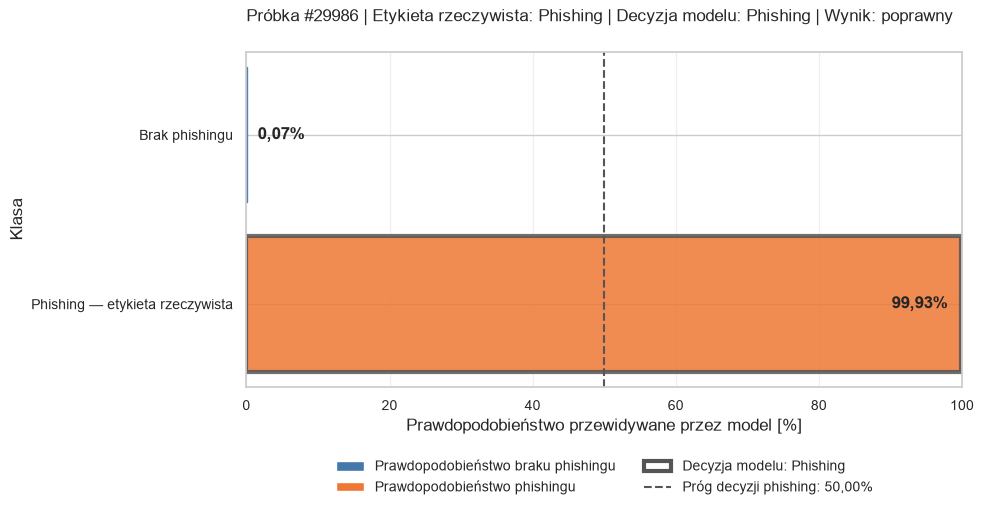

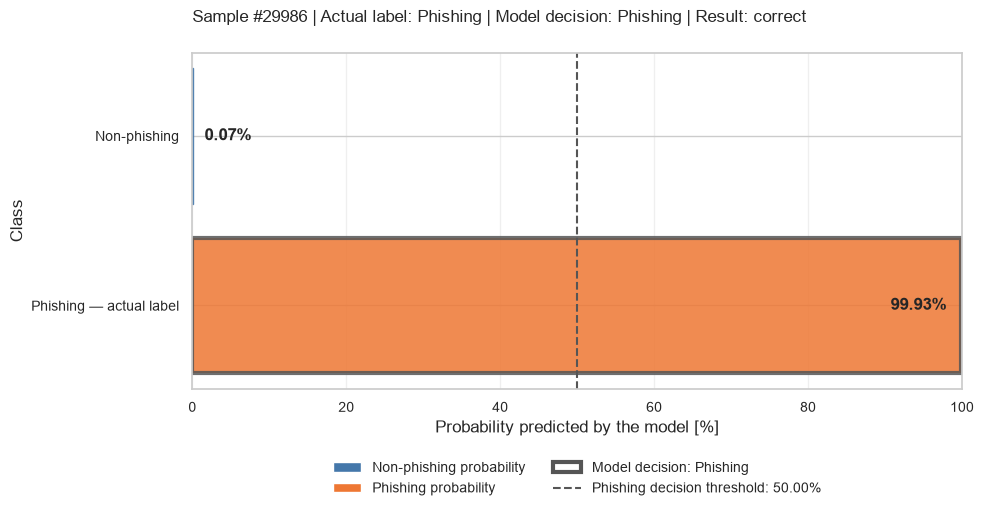

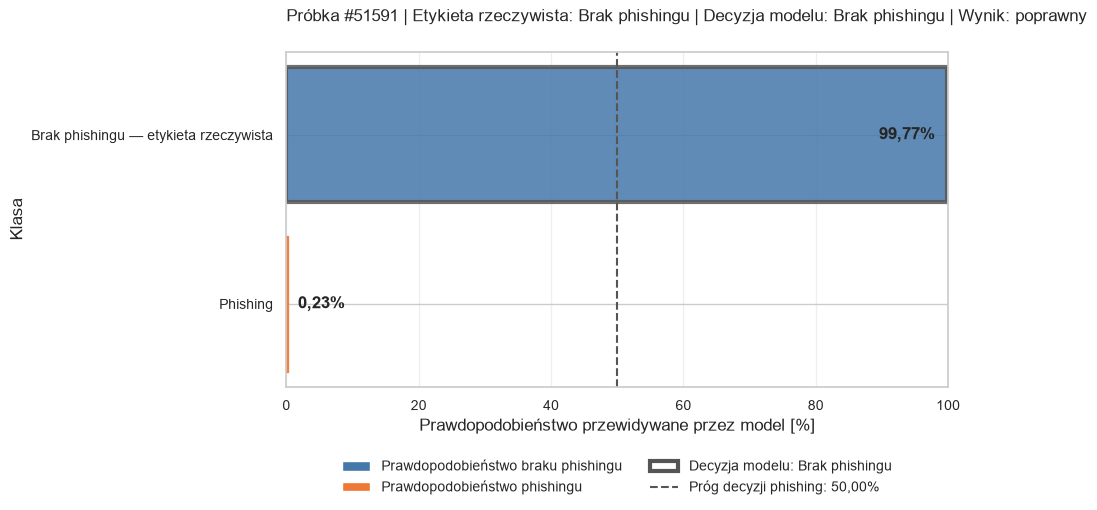

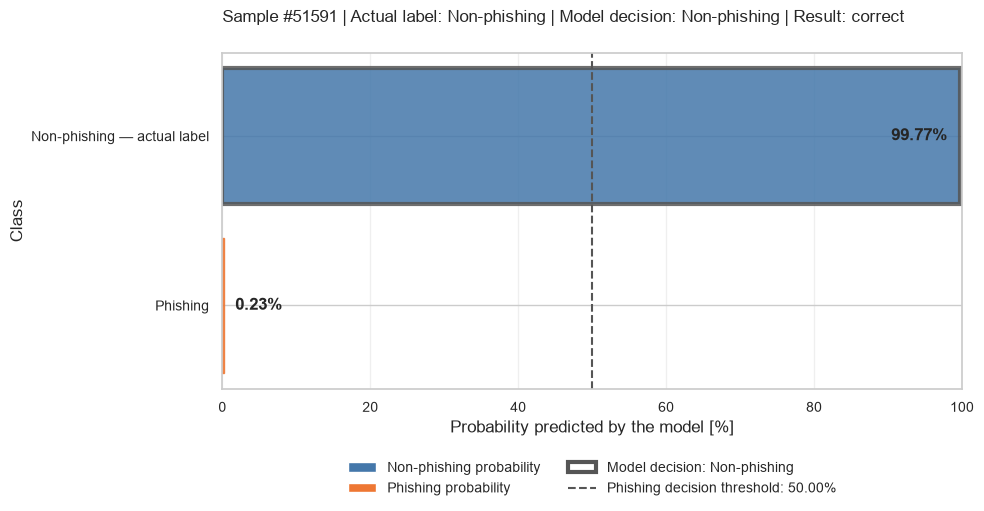

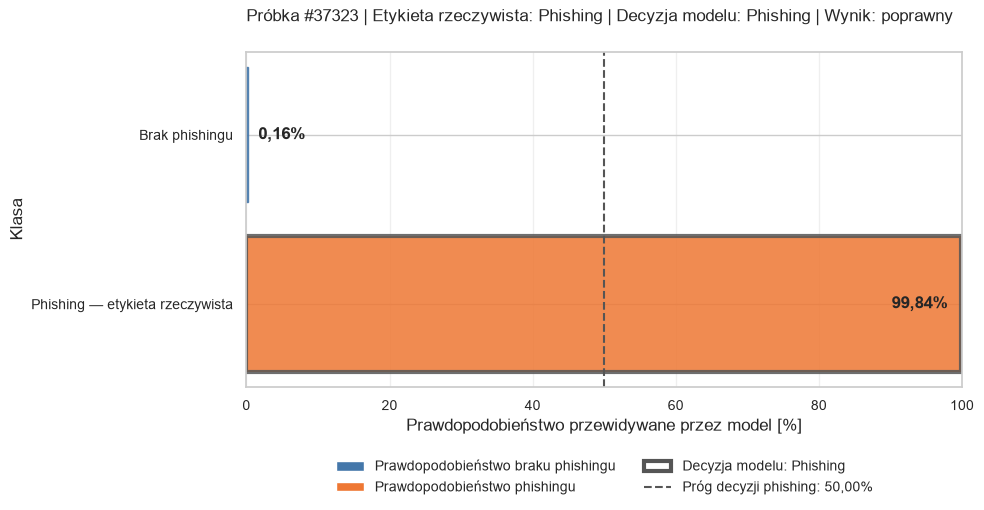

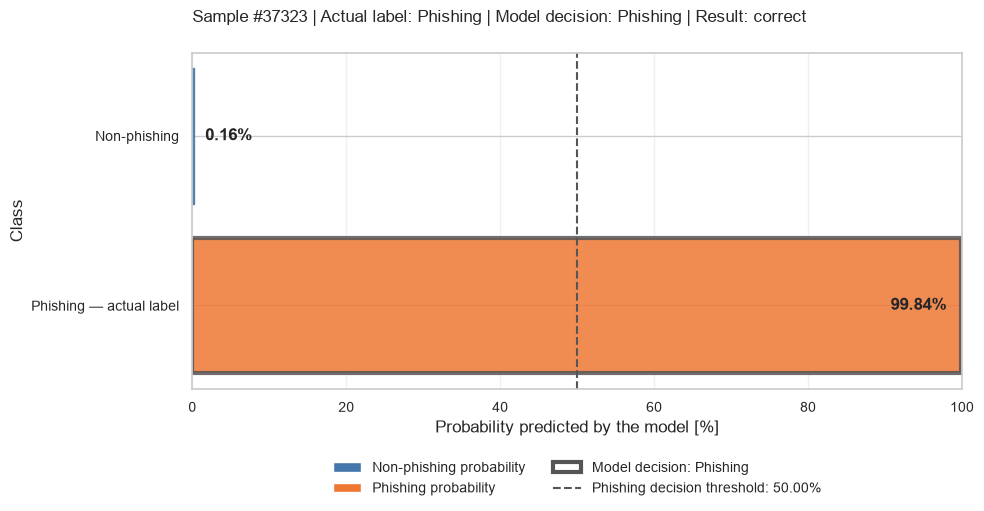

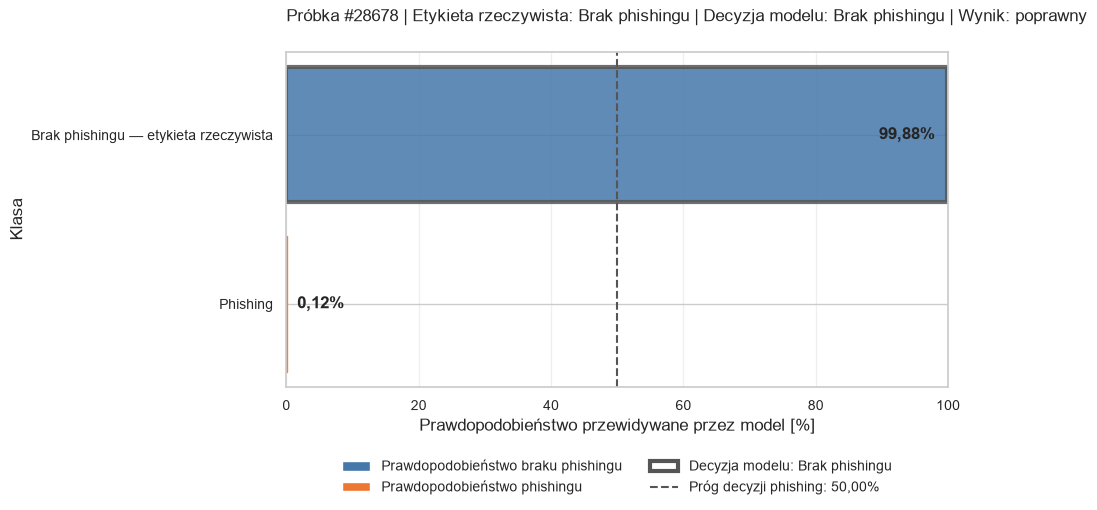

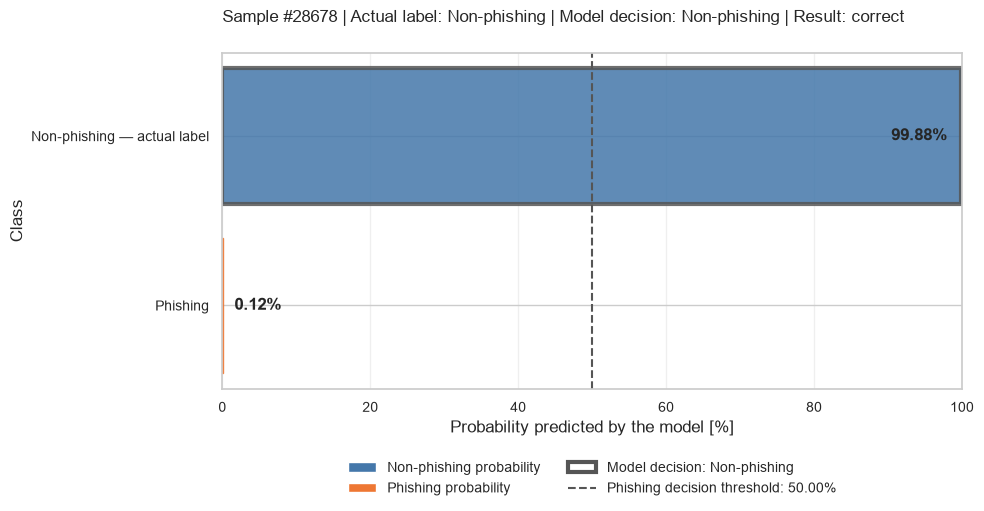

In [13]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    true_labels = results_for_datasets[dataset_name]['y_test']
    label_values = np.asarray(true_labels, dtype=int)
    probabilities = np.asarray(
        evaluation_results[dataset_name]['y_pred_proba'], dtype=float
    ).reshape(-1)
    threshold = evaluation_results[dataset_name].get('decision_threshold', 0.5)
    sample_positions = {
        'phishing': int(np.flatnonzero(label_values == 1)[0]),
        'bez_phishingu': int(np.flatnonzero(label_values == 0)[0]),
    }
    for sample_kind, position in sample_positions.items():
        sample_id = (
            true_labels.index[position]
            if hasattr(true_labels, 'index') else position
        )
        for language in ['pl', 'en']:
            language_folder = 'pl' if language == 'pl' else 'eng'
            figure, _ = plot_sample_probability_prediction(
                probabilities[position], label_values[position], sample_id,
                decision_threshold=threshold, language=language,
            )
            save_dataset_figure(
                figure, PLOTS_DIR, dataset_name,
                f'{language_folder}/xgboost_sample_prediction_{sample_kind}.png',
            )
            plt.show()
    for obsolete_name in [
        'xgboost_prediction_example_phishing.png',
        'xgboost_prediction_example_bez_phishingu.png',
        'xgboost_prediction_examples.png',
        'xgboost_probability_distribution.png',
        'xgboost_sample_prediction_phishing.png',
        'xgboost_sample_prediction_bez_phishingu.png',
        'xgboost_sample_prediction_phishing_pl.png',
        'xgboost_sample_prediction_phishing_en.png',
        'xgboost_sample_prediction_bez_phishingu_pl.png',
        'xgboost_sample_prediction_bez_phishingu_en.png',
    ]:
        remove_dataset_figure(PLOTS_DIR, dataset_name, obsolete_name)


## 7.2. Krzywe uczenia w pięciokrotnej walidacji krzyżowej

Oś pozioma przedstawia dziesięć rosnących rozmiarów podzbioru uczącego: od
10% do 100% danych dostępnych do uczenia w danym podziale. Dla każdego rozmiaru
model jest dopasowywany w pięciu podziałach. Każdy punkt linii uczenia jest
średnią miary obliczonej na pięciu podzbiorach uczących, a każdy punkt linii
walidacji jest średnią miary obliczonej na pięciu odpowiadających im
podzbiorach walidacyjnych. Pasmo oznacza ± jedno odchylenie standardowe.
Oś pozioma nie przedstawia liczby próbek walidacyjnych ani testowych.

Walidacja służy do oceny uogólniania modelu podczas jego opracowywania.
Nie jest testem końcowym. Niezależny zbiór testowy nie uczestniczy w
wyznaczaniu tych krzywych; porównanie końcowych wyników uczenia i testowania
znajduje się w sekcji ewaluacji modelu.


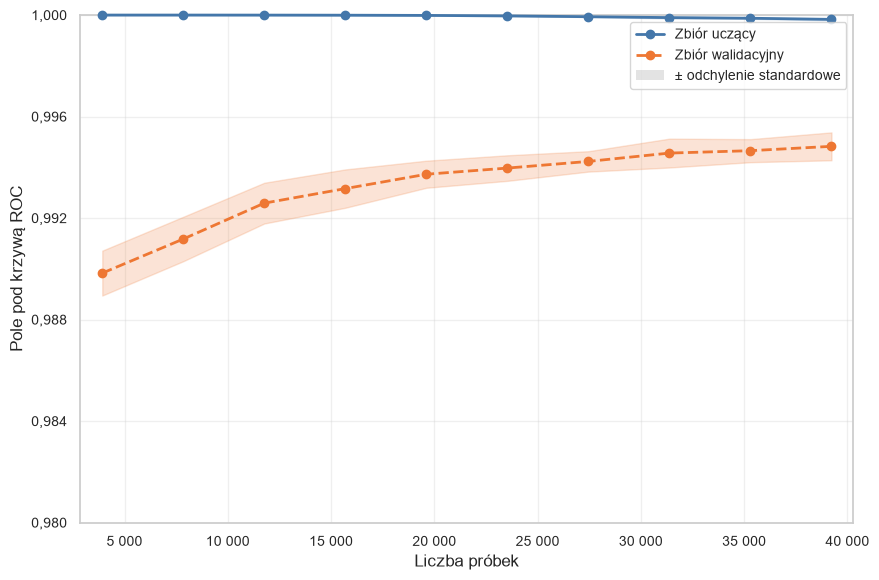

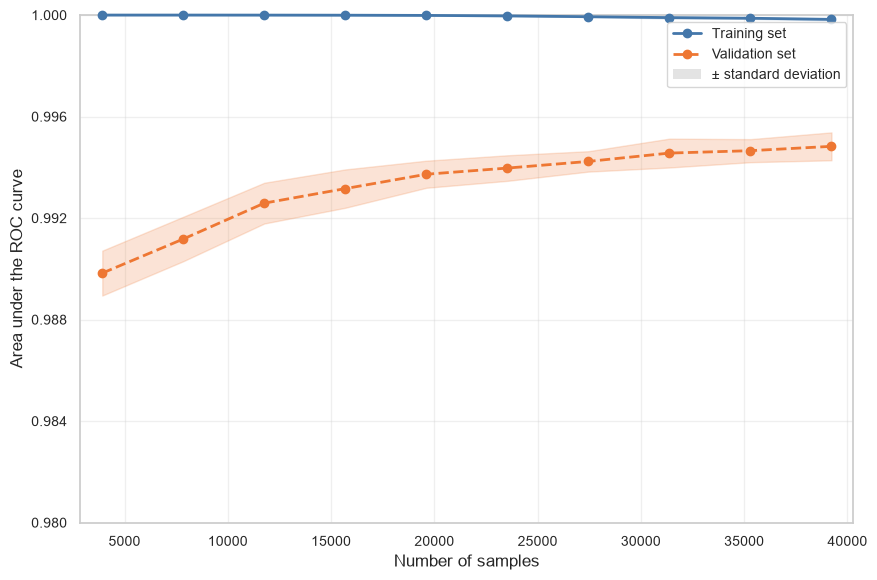

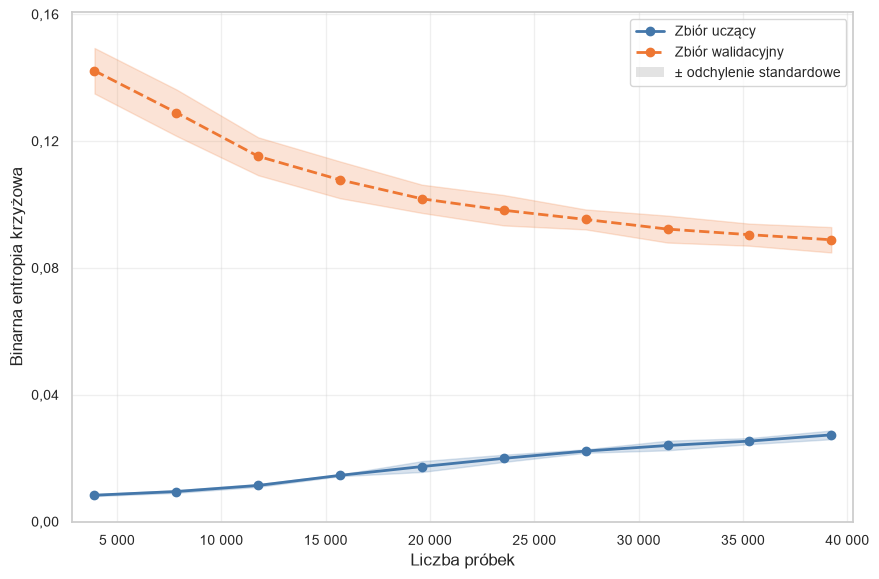

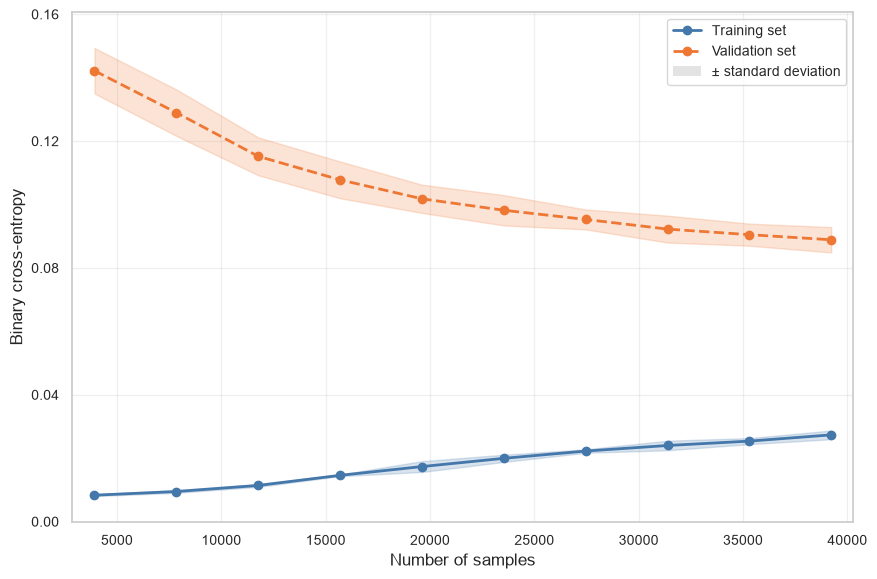

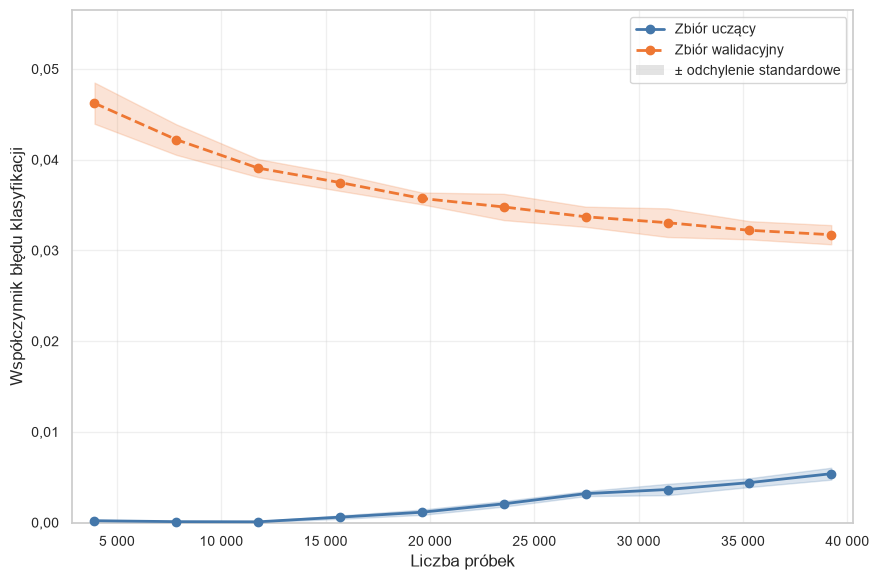

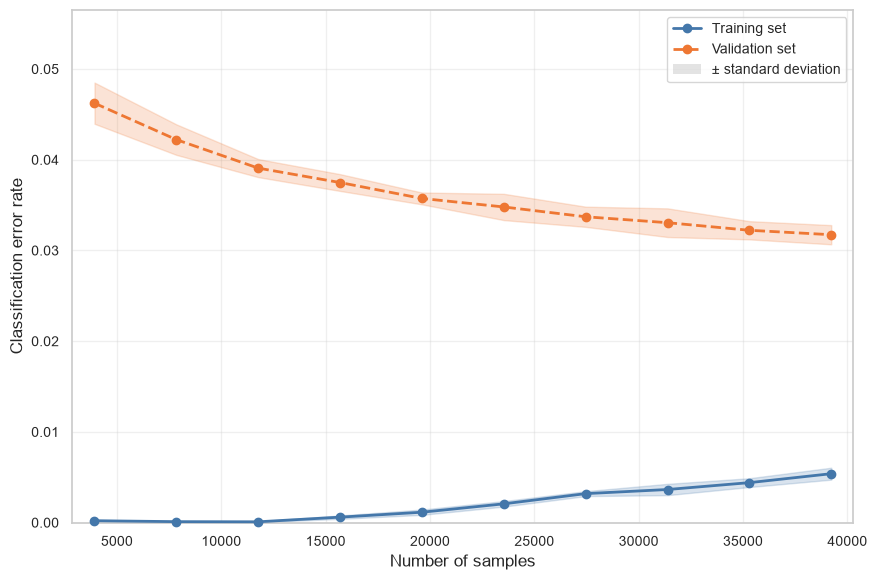

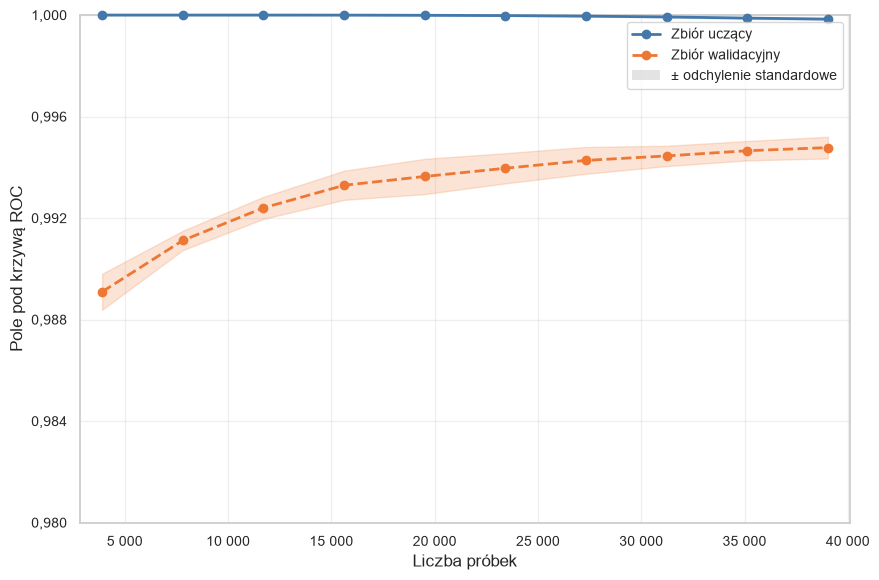

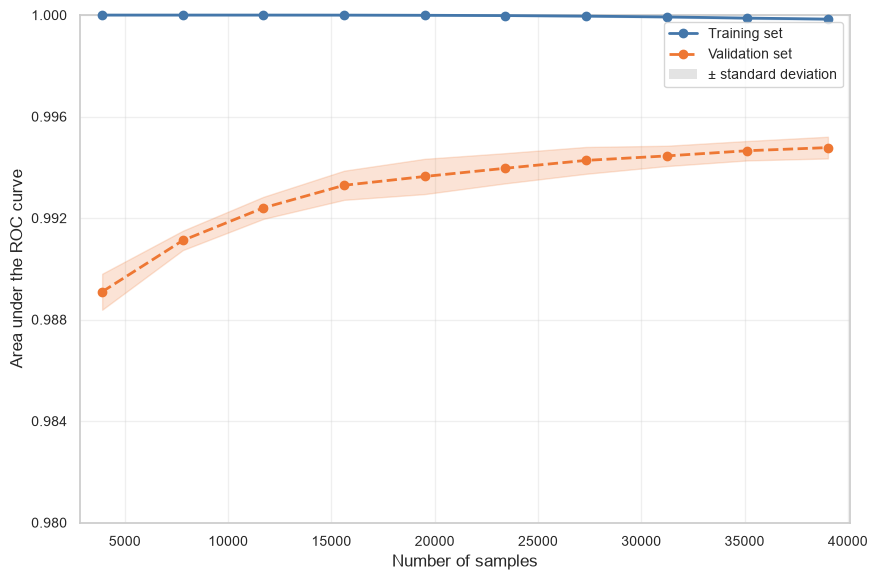

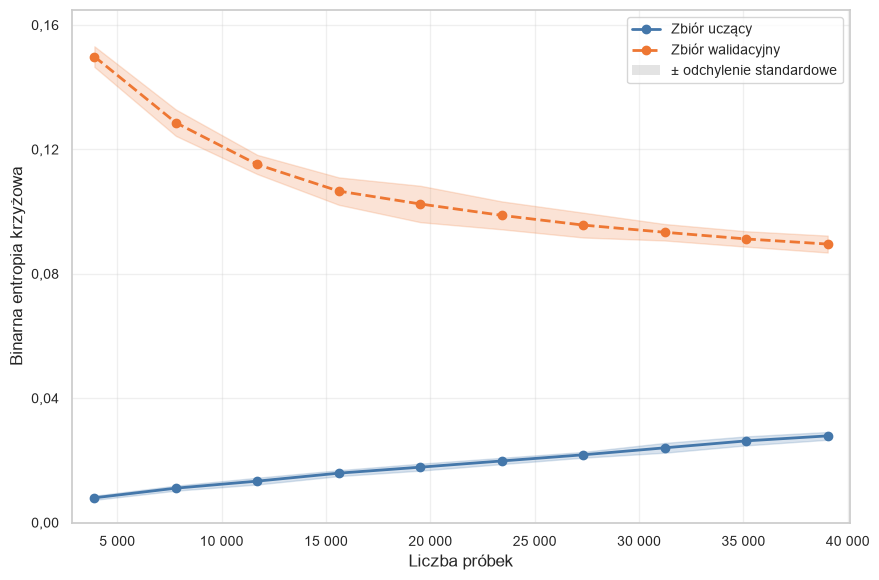

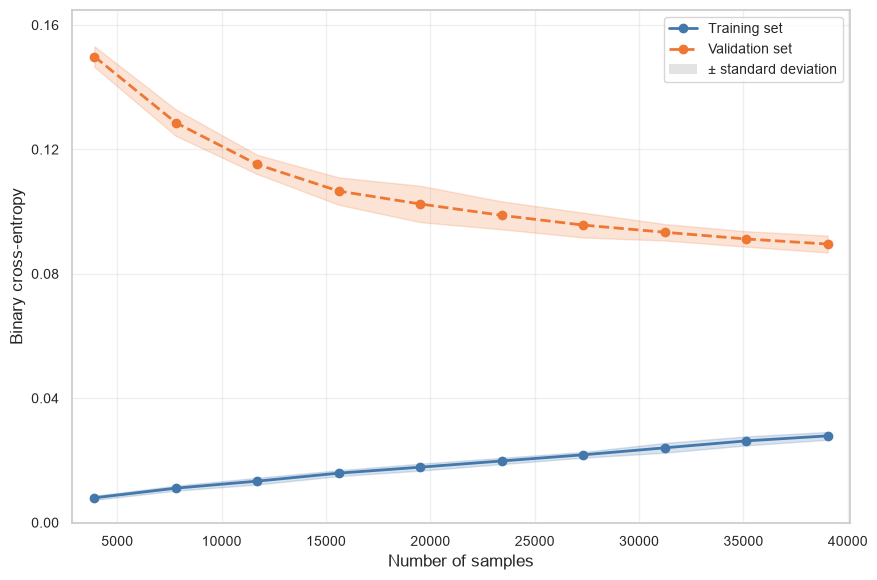

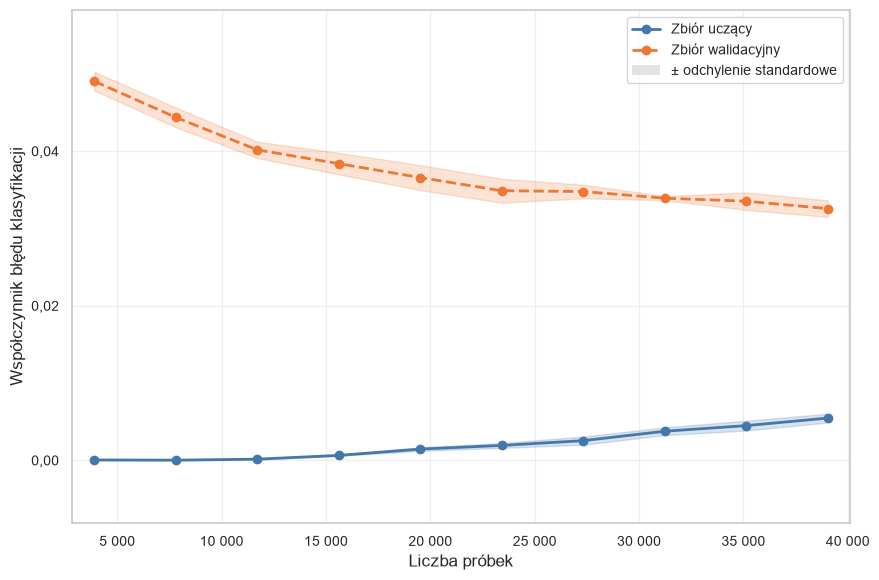

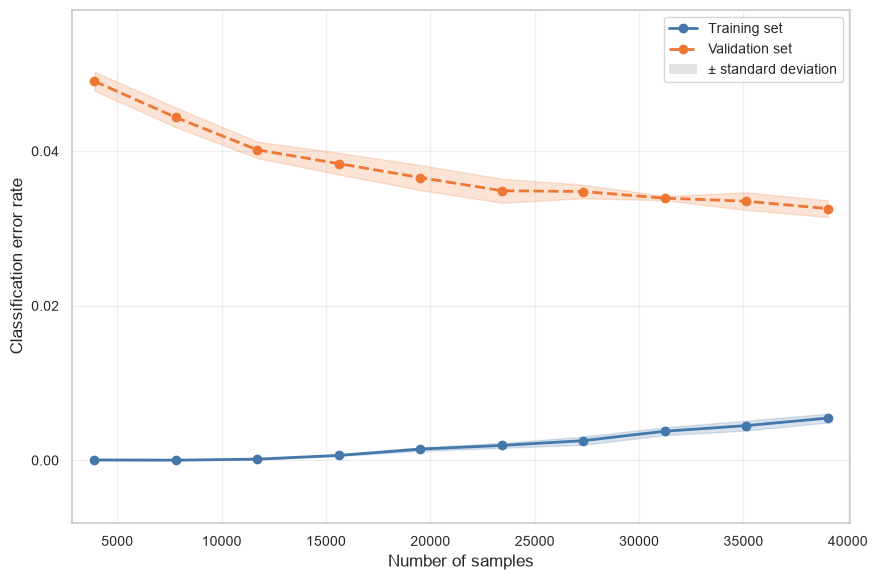

In [14]:
learning_results = {}
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    model = results_for_datasets[dataset_name]['model']
    X_curve = results_for_datasets[dataset_name]['X_train']
    y_curve = results_for_datasets[dataset_name]['y_train']

    train_sizes, train_scores, validation_scores = learning_curve(
        model, results_for_datasets[dataset_name]['X_train'], results_for_datasets[dataset_name]['y_train'], cv=5, scoring='roc_auc', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    _, train_log_loss, validation_log_loss = learning_curve(
        model, X_curve, y_curve, cv=5, scoring='neg_log_loss', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    _, train_accuracy, validation_accuracy = learning_curve(
        model, X_curve, y_curve, cv=5, scoring='accuracy', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    learning_results[dataset_name] = {
        'x': train_sizes,
        'train_mean': train_scores.mean(axis=1),
        'train_std': train_scores.std(axis=1),
        'validation_mean': validation_scores.mean(axis=1),
        'validation_std': validation_scores.std(axis=1),
        'train_log_loss_mean': (-train_log_loss).mean(axis=1),
        'train_log_loss_std': (-train_log_loss).std(axis=1),
        'validation_log_loss_mean': (-validation_log_loss).mean(axis=1),
        'validation_log_loss_std': (-validation_log_loss).std(axis=1),
        'train_error_rate_mean': (1.0 - train_accuracy).mean(axis=1),
        'train_error_rate_std': train_accuracy.std(axis=1),
        'validation_error_rate_mean': (1.0 - validation_accuracy).mean(axis=1),
        'validation_error_rate_std': validation_accuracy.std(axis=1),
    }

for dataset_name, values in learning_results.items():
    figure, _ = plot_score_curve(
        values['x'], values['train_mean'], values['train_std'],
        values['validation_mean'], values['validation_std'],
        x_label='Liczba próbek',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'xgboost_learning_curves.png')
    plt.show()

    figure, _ = plot_score_curve(
        values['x'], values['train_log_loss_mean'], values['train_log_loss_std'],
        values['validation_log_loss_mean'], values['validation_log_loss_std'],
        x_label='Liczba próbek',
        y_label='Binarna entropia krzyżowa',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'xgboost_bce_learning_curves.png')
    plt.show()

    figure, _ = plot_score_curve(
        values['x'], values['train_error_rate_mean'], values['train_error_rate_std'],
        values['validation_error_rate_mean'], values['validation_error_rate_std'],
        x_label='Liczba próbek',
        y_label='Współczynnik błędu klasyfikacji',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'xgboost_error_rate_learning_curves.png')
    plt.show()


## 7.3. Wpływ liczby estymatorów (n_estimators) na skuteczność modelu


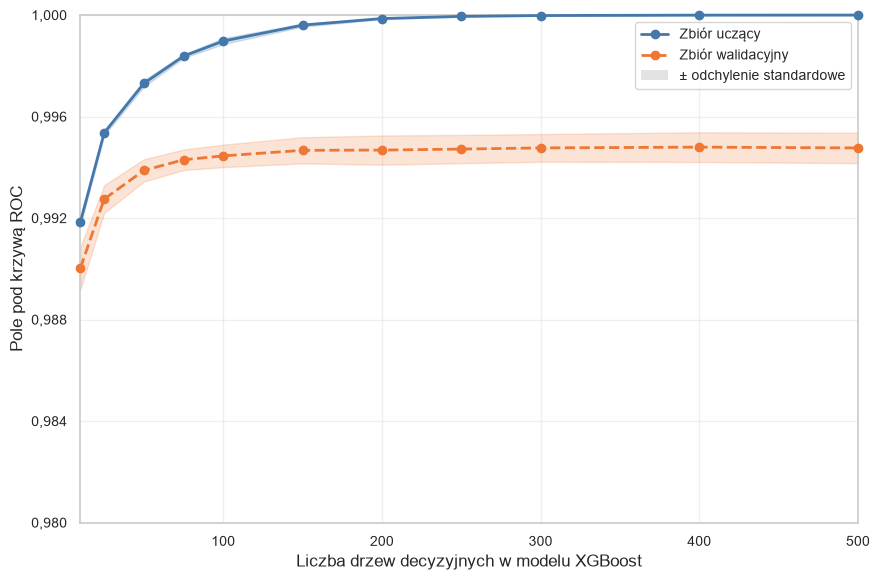

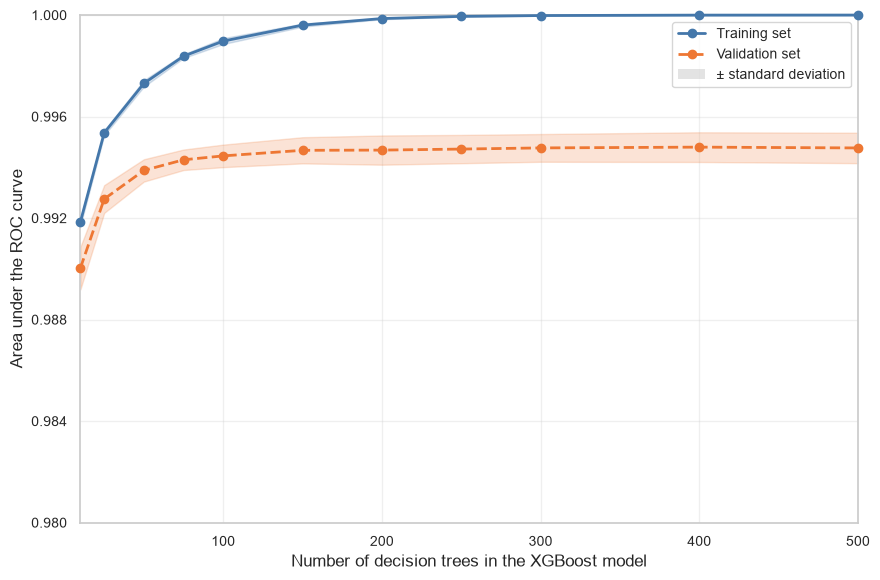

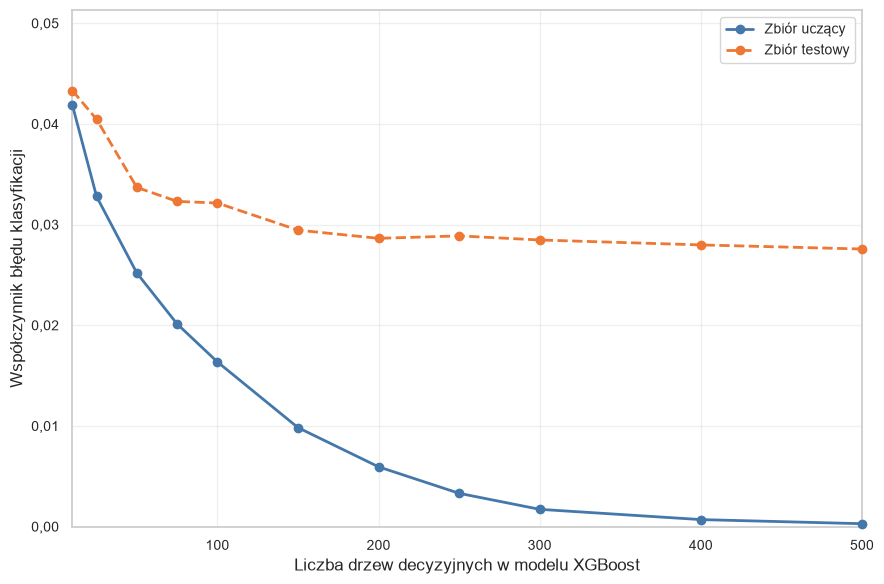

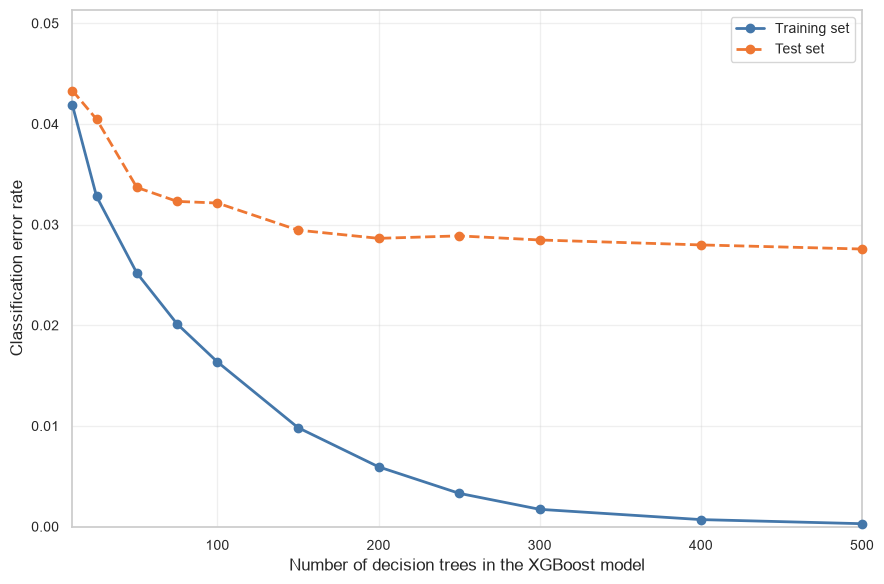

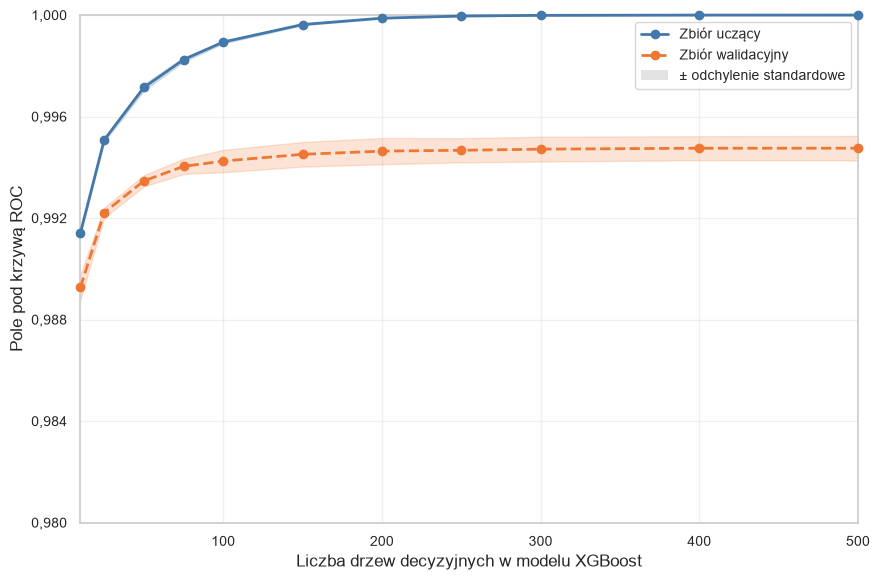

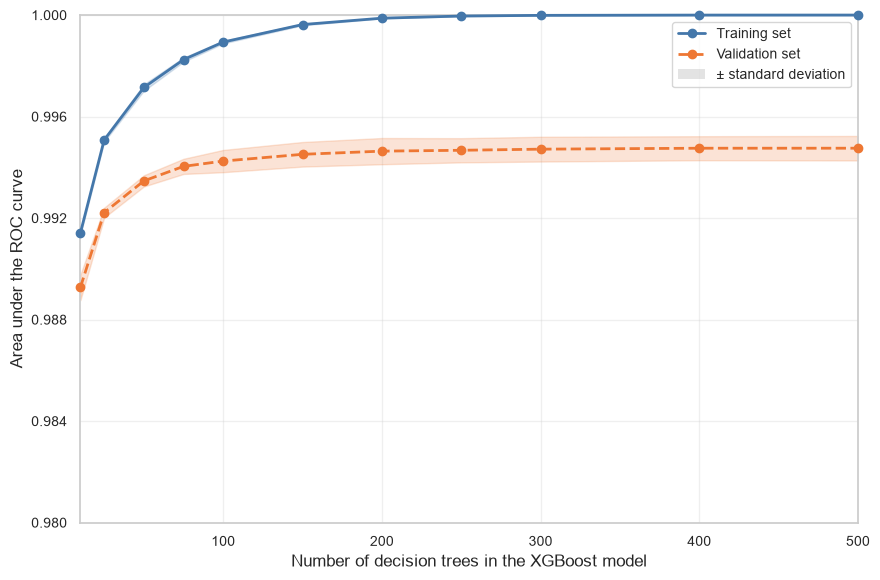

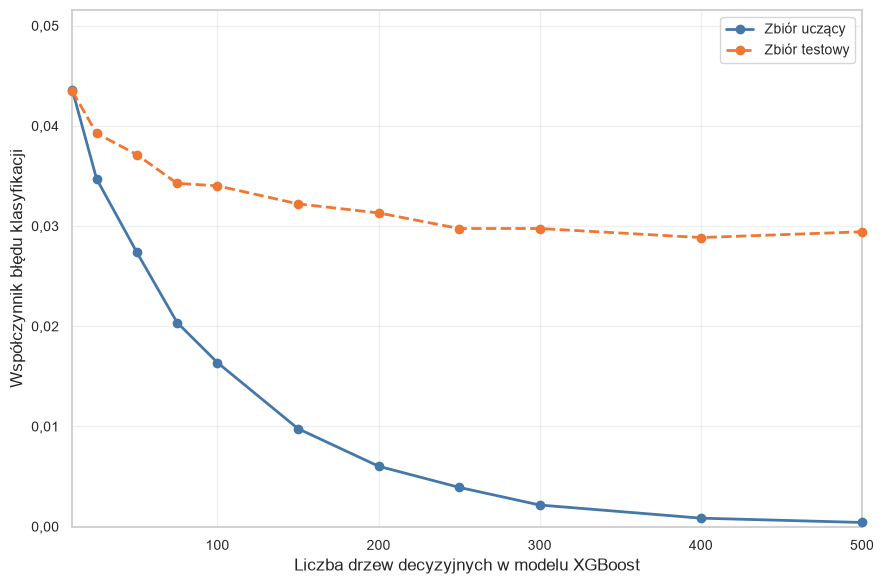

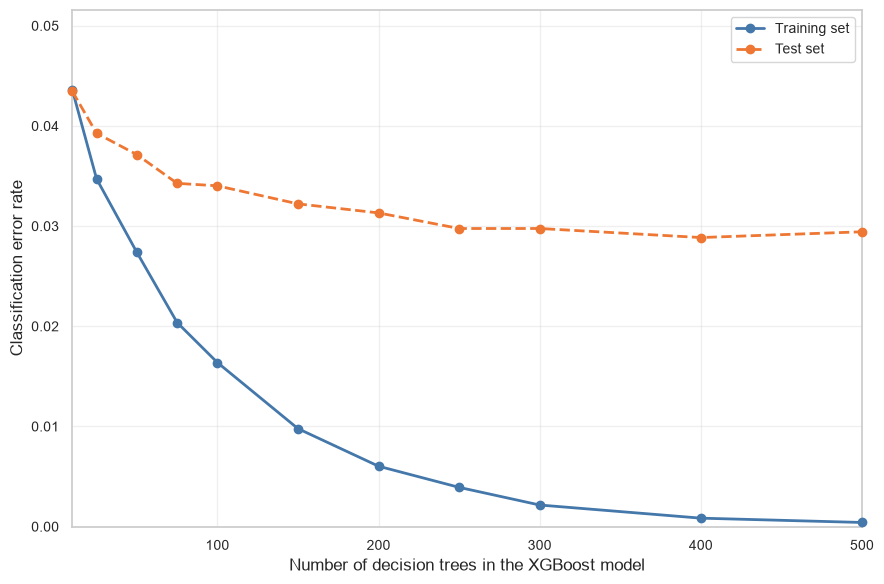

In [15]:
validation_results = {}
param_range = np.array([10, 25, 50, 75, 100, 150, 200, 250, 300, 400, 500])
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    X_curve = results_for_datasets[dataset_name]['X_train']
    y_curve = results_for_datasets[dataset_name]['y_train']
    X_test_curve = results_for_datasets[dataset_name]['X_test']
    y_test_curve = results_for_datasets[dataset_name]['y_test']

    model_base = XGBClassifier(random_state=42, n_jobs=-1, use_label_encoder=False, eval_metric='logloss')
    train_scores, validation_scores = validation_curve(
        model_base, X_curve, y_curve, param_name='n_estimators', param_range=param_range,
        cv=5, scoring='roc_auc', n_jobs=-1,
    )
    validation_results[dataset_name] = {
        'train_mean': train_scores.mean(axis=1),
        'train_std': train_scores.std(axis=1),
        'validation_mean': validation_scores.mean(axis=1),
        'validation_std': validation_scores.std(axis=1),
        'train_errors': [],
        'test_errors': [],
    }
    for parameter_value in param_range:
        parameter_model = XGBClassifier(
            n_estimators=int(parameter_value), random_state=42, n_jobs=-1,
            use_label_encoder=False, eval_metric='logloss',
        )
        parameter_model.fit(X_curve, y_curve)
        validation_results[dataset_name]['train_errors'].append(
            1.0 - accuracy_score(y_curve, parameter_model.predict(X_curve))
        )
        validation_results[dataset_name]['test_errors'].append(
            1.0 - accuracy_score(y_test_curve, parameter_model.predict(X_test_curve))
        )

for dataset_name, values in validation_results.items():
    figure, _ = plot_score_curve(
        param_range, values['train_mean'], values['train_std'],
        values['validation_mean'], values['validation_std'],
        x_label='Liczba drzew decyzyjnych w modelu XGBoost', logarithmic_x=False,
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'xgboost_validation_curves.png')
    plt.show()
    figure, _ = plot_parameter_train_test_error(
        param_range, values['train_errors'], values['test_errors'],
        x_label='Liczba drzew decyzyjnych w modelu XGBoost', logarithmic_x=False,
    )
    remove_dataset_figure(PLOTS_DIR, dataset_name, 'xgboost_parameter_train_validation_error.png')
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'xgboost_parameter_train_test_error.png')
    plt.show()


## 7.5. Ważność cech w obu modelach


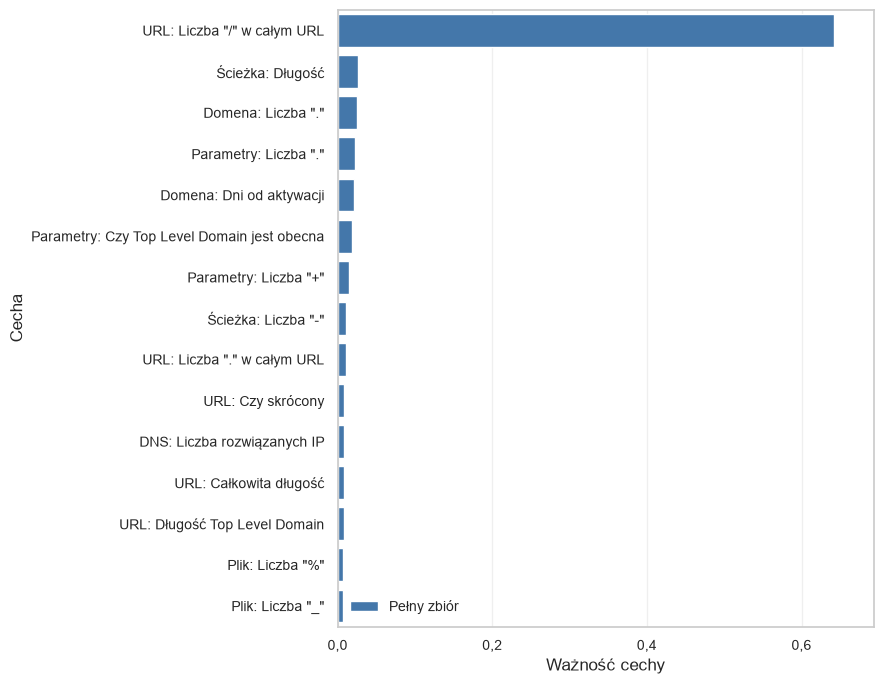

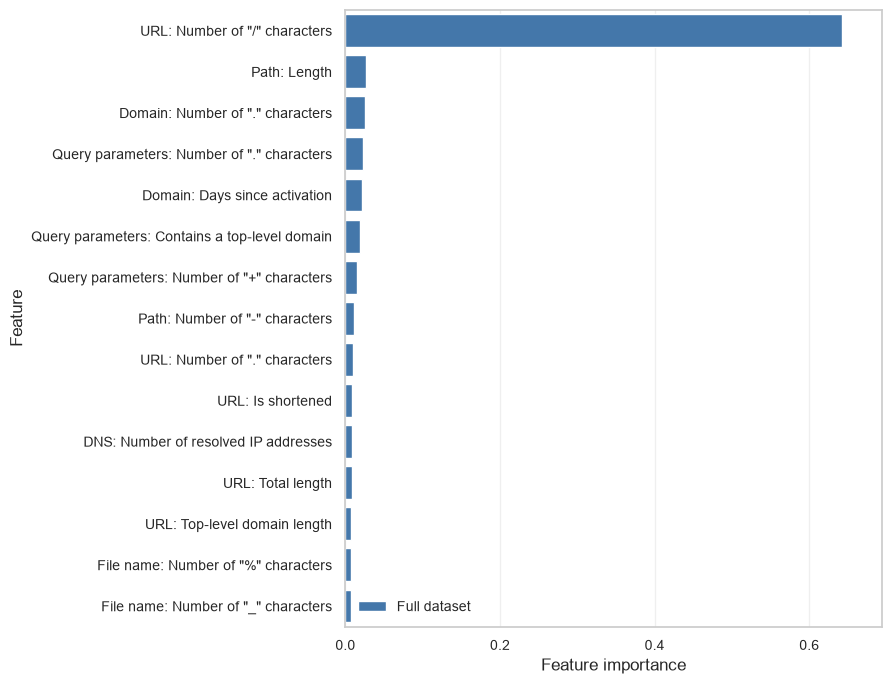

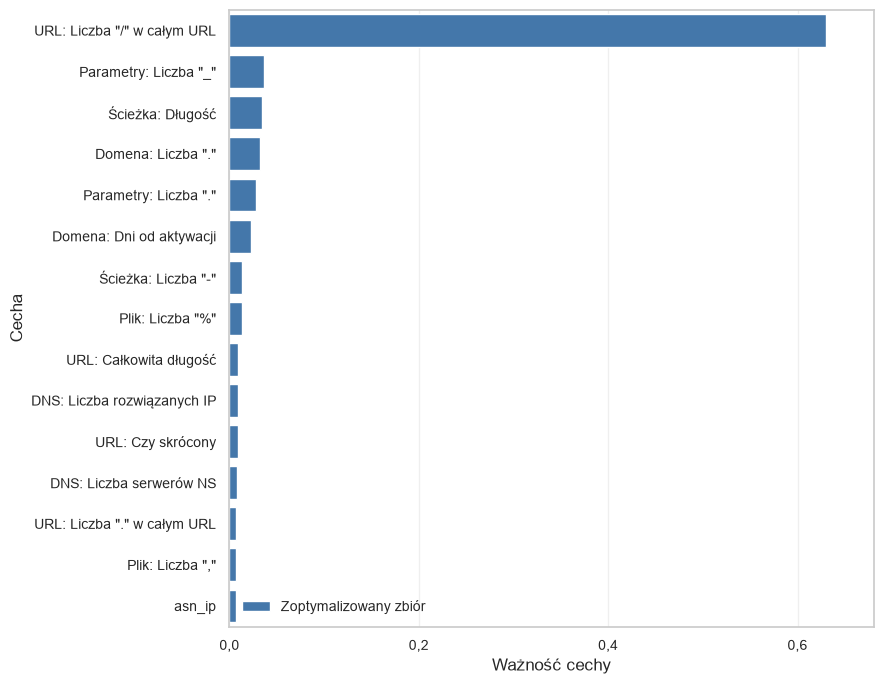

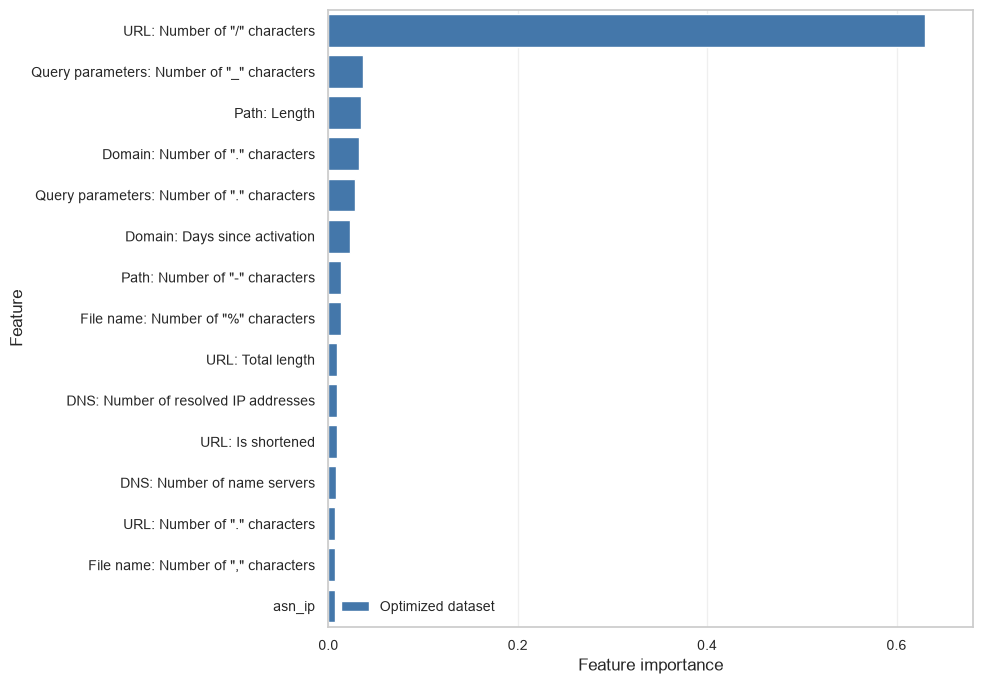

In [16]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    model = results_for_datasets[dataset_name]['model']
    X_features = results_for_datasets[dataset_name]['X_train']
    feature_importance = pd.DataFrame({
        'Cecha': [get_readable_name(column) for column in X_features.columns],
        'Ważność': model.feature_importances_,
    }).sort_values('Ważność', ascending=False).head(15)
    figure, _ = plot_feature_ranking(
        feature_importance, dataset_name, x_column='Ważność', x_label='Ważność cechy'
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'xgboost_feature_importance.png')
    plt.show()


## 8. Zapis modeli i wyników


In [17]:
os.makedirs('../data', exist_ok=True)

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{'='*60}")
    print(f"ZAPISYWANIE MODELU - {dataset_name.upper()}")
    print(f"{'='*60}")

    model = results_for_datasets[dataset_name]['model']
    best_params = results_for_datasets[dataset_name]['best_params']
    X = data_splits[dataset_name]['X']

    model_data = {
        'model': model,
        'scaler': None,
        'feature_names': X.columns.tolist(),
        'best_params': best_params,
        'metrics': {
            'accuracy': evaluation_results[dataset_name]['accuracy'],
            'precision': evaluation_results[dataset_name]['precision'],
            'recall': evaluation_results[dataset_name]['recall'],
            'f1': evaluation_results[dataset_name]['f1'],
            'auc_roc': evaluation_results[dataset_name]['auc_roc'],
            'cv_mean': evaluation_results[dataset_name]['cv_mean'],
            'cv_std': evaluation_results[dataset_name]['cv_std']
        }
    }

    file_suffix = 'full' if dataset_name == 'Pełny zbiór' else 'optimized'

    model_path = f'{MODELS_DIR}/xgboost_model_{file_suffix}.pkl'
    with open(model_path, 'wb') as f:
        pickle.dump(model_data, f)
    print(f"✓ Model zapisany: {model_path}")

comparison_df = pd.DataFrame({
    'Zbiór danych': ['Pełny zbiór', 'Zoptymalizowany zbiór'],
    'Dokładność': [evaluation_results[name]['accuracy'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Precyzja': [evaluation_results[name]['precision'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Czułość': [evaluation_results[name]['recall'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Miara F1': [evaluation_results[name]['f1'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'AUC-ROC': [evaluation_results[name]['auc_roc'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Średnia CV AUC': [evaluation_results[name]['cv_mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Odchylenie CV AUC': [evaluation_results[name]['cv_std'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Czas uczenia (s)': [results_for_datasets[name]['training_time'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Liczba cech': [data_splits[name]['feature_count'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Średnie CPU [%]': [results_for_datasets[name]['resource_stats']['cpu']['mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Maksymalne CPU [%]': [results_for_datasets[name]['resource_stats']['cpu']['max'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Średni RAM [GB]': [results_for_datasets[name]['resource_stats']['ram']['mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Maksymalny RAM [GB]': [results_for_datasets[name]['resource_stats']['ram']['max'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Próbki pomiarowe': [results_for_datasets[name]['resource_stats']['samples'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
})

comparison_path = backend_root.parent / 'results' / 'original' / 'model_comparisons' / 'xgboost_comparison.csv'
comparison_path.parent.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(comparison_path, index=False)
print(f"\n✓ Porównanie zapisane: {comparison_path}")

print(f"\n{'='*80}")
print("PODSUMOWANIE KOŃCOWE")
print(f"{'='*80}")

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{dataset_name.upper()}:")
    print(f"  Liczba cech: {len(data_splits[dataset_name]['X'].columns)}")
    print(f"  Dokładność: {evaluation_results[dataset_name]['accuracy']:.4f}")
    print(f"  F1-Score: {evaluation_results[dataset_name]['f1']:.4f}")
    print(f"  AUC-ROC: {evaluation_results[dataset_name]['auc_roc']:.4f}")
    print(f"  Czas trenowania: {results_for_datasets[dataset_name]['training_time']:.2f}s")

print(f"\n✅ Wszystkie modele i wizualizacje zostały zapisane!")
print(f"Wizualizacje zapisane w: {PLOTS_DIR}/")
print(f"Modele zapisane w: {MODELS_DIR}/")



ZAPISYWANIE MODELU - PEŁNY ZBIÓR
✓ Model zapisany: ../models/xgboost/xgboost_model_full.pkl

ZAPISYWANIE MODELU - ZOPTYMALIZOWANY ZBIÓR
✓ Model zapisany: ../models/xgboost/xgboost_model_optimized.pkl

✓ Porównanie zapisane: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/model_comparisons/xgboost_comparison.csv

PODSUMOWANIE KOŃCOWE

PEŁNY ZBIÓR:
  Liczba cech: 111
  Dokładność: 0.9714
  F1-Score: 0.9715
  AUC-ROC: 0.9953
  Czas trenowania: 0.78s

ZOPTYMALIZOWANY ZBIÓR:
  Liczba cech: 74
  Dokładność: 0.9698
  F1-Score: 0.9698
  AUC-ROC: 0.9949
  Czas trenowania: 0.69s

✅ Wszystkie modele i wizualizacje zostały zapisane!
Wizualizacje zapisane w: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/xgboost/
Modele zapisane w: ../models/xgboost/
